<a href="https://colab.research.google.com/github/chaimaao0/CoastGuard/blob/feature%2Fai-model/CoastGuard_TN_Phases1_to_6_Complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CoastGuard TN


## Setup 1 — Upload NetCDF dataset

In [2]:
from google.colab import files
uploaded = files.upload()
nc_file = next((n for n in uploaded if n.lower().endswith(".nc")), None)
if nc_file is None:
    raise FileNotFoundError("Upload GlobalWaterlineDataset.nc")
print("Uploaded:", nc_file)

Saving GlobalWaterlineDataset.nc to GlobalWaterlineDataset.nc
Uploaded: GlobalWaterlineDataset.nc


## Setup 2 — Install and import libraries

In [3]:
!pip -q install xarray netCDF4
import os, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", 40)

## Setup 3 — Open and inspect dataset

In [4]:
ds = xr.open_dataset(nc_file)
display(ds)
print("Dimensions:", dict(ds.sizes))
print("Variables:", list(ds.data_vars))
print("Coordinates:", list(ds.coords))
print("Attributes:", ds.attrs)

<xarray.Dataset> Size: 138MB
Dimensions:           (lon: 8841, time: 324, lat: 8841)
Coordinates:
  * lon               (lon) float64 71kB 170.2 166.3 165.1 ... 81.77 81.55 81.24
  * time              (time) float64 3kB 1.993e+05 1.993e+05 ... 2.019e+05
  * lat               (lat) float64 71kB 59.99 59.81 59.85 ... 6.621 6.361 6.175
Data variables:
    X                 (lon, time) float64 23MB ...
    River_drivers     (lon, time) float64 23MB ...
    SLA_drivers       (lon, time) float64 23MB ...
    Wave_Hs_drivers   (lon, time) float64 23MB ...
    Wave_Tp_drivers   (lon, time) float64 23MB ...
    Wave_Dir_drivers  (lon, time) float64 23MB ...

Dimensions: {'lon': 8841, 'time': 324, 'lat': 8841}
Variables: ['X', 'River_drivers', 'SLA_drivers', 'Wave_Hs_drivers', 'Wave_Tp_drivers', 'Wave_Dir_drivers']
Coordinates: ['time', 'lon', 'lat']
Attributes: {}


# PHASE 1 — Exploratory Data Analysis (EDA)

## 1.1 — Inspect variables and dimensions

In [5]:
for name, da in ds.data_vars.items():
    print(f"{name}: dimensions={da.dims}, shape={da.shape}, dtype={da.dtype}")

X: dimensions=('lon', 'time'), shape=(8841, 324), dtype=float64
River_drivers: dimensions=('lon', 'time'), shape=(8841, 324), dtype=float64
SLA_drivers: dimensions=('lon', 'time'), shape=(8841, 324), dtype=float64
Wave_Hs_drivers: dimensions=('lon', 'time'), shape=(8841, 324), dtype=float64
Wave_Tp_drivers: dimensions=('lon', 'time'), shape=(8841, 324), dtype=float64
Wave_Dir_drivers: dimensions=('lon', 'time'), shape=(8841, 324), dtype=float64


## 1.2 — Global data quality

In [6]:
candidate_variables = ["X","River_drivers","SLA_drivers","Wave_Hs_drivers","Wave_Tp_drivers","Wave_Dir_drivers"]
variables = [v for v in candidate_variables if v in ds.data_vars]
quality_rows=[]
for var in variables:
    a=np.asarray(ds[var].values); total=a.size; valid=int(np.isfinite(a).sum())
    quality_rows.append({"Variable":var,"Total":total,"Valid":valid,"Missing":total-valid,
                         "Missing_Percent":round(100*(total-valid)/total,2)})
quality_df=pd.DataFrame(quality_rows)
display(quality_df)

,Variable,Total,Valid,Missing,Missing_Percent
0,X,2864484,2761757,102727,3.59
1,River_drivers,2864484,2436203,428281,14.95
2,SLA_drivers,2864484,2864484,0,0.00
3,Wave_Hs_drivers,2864484,2864484,0,0.00
4,Wave_Tp_drivers,2864484,2864484,0,0.00
5,Wave_Dir_drivers,2864484,2864484,0,0.00


## 1.3 — Data availability by site

In [7]:
availability_rows=[]
for var in [v for v in ["X","River_drivers"] if v in ds.data_vars]:
    da=ds[var]
    if da.ndim != 2:
        print("Skipping non-2D variable:",var); continue
    site_dim,time_dim=da.dims
    counts=da.notnull().sum(dim=time_dim).values
    for i,n in enumerate(counts):
        availability_rows.append({"Variable":var,"Site_Index":i,"Valid_Months":int(n),
                                  "Missing_Months":int(da.sizes[time_dim]-n)})
availability_df=pd.DataFrame(availability_rows)
display(availability_df.groupby("Variable").agg(
    Sites_With_Missing=("Missing_Months",lambda x:int((x>0).sum())),
    Sites_With_Zero_Valid=("Valid_Months",lambda x:int((x==0).sum())),
    Min_Valid=("Valid_Months","min"),Median_Valid=("Valid_Months","median")).reset_index())

,Variable,Sites_With_Missing,Sites_With_Zero_Valid,Min_Valid,Median_Valid
0,River_drivers,8841,1204,0,319.0
1,X,3482,1,0,324.0


## 1.4 — Descriptive statistics for X

In [8]:
if "X" not in ds: raise KeyError("X variable not found")
x_all=np.asarray(ds["X"].values,dtype=float)
x_valid=x_all[np.isfinite(x_all)]
display(pd.Series(x_valid).describe(percentiles=[.01,.25,.5,.75,.99]).to_frame("X_m").round(3))

,X_m
count,2761757.000
mean,0.150
std,23.583
min,-1172.609
1%,-39.295
25%,-4.784
50%,0.108
75%,4.869
99%,36.440
max,1412.146


## 1.5 — X distribution plots

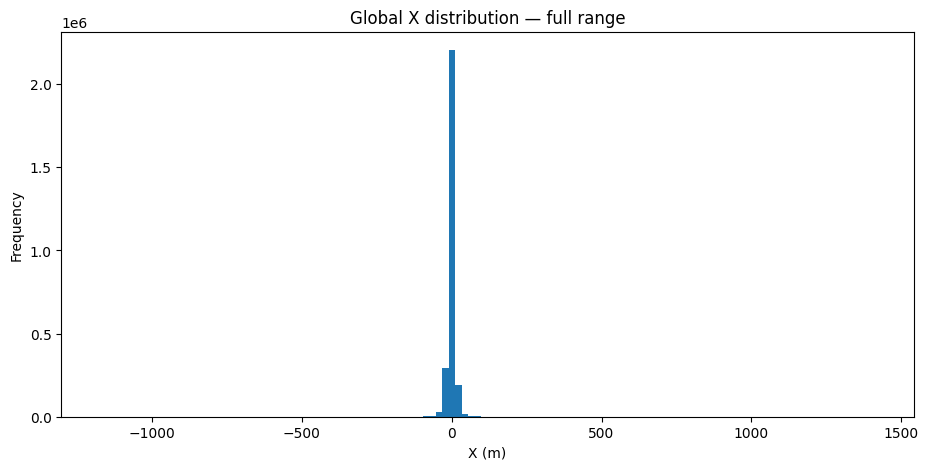

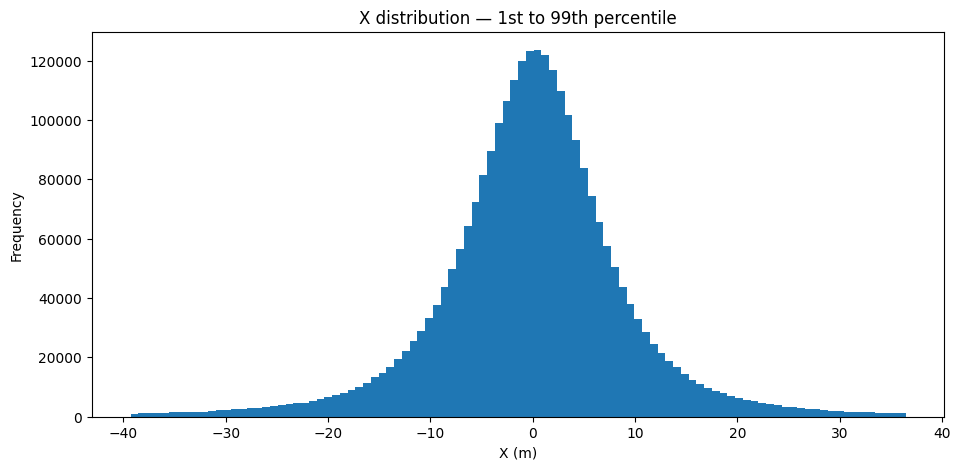

In [9]:
plt.figure(); plt.hist(x_valid,bins=120); plt.title("Global X distribution — full range")
plt.xlabel("X (m)"); plt.ylabel("Frequency"); plt.show()
p01,p99=np.percentile(x_valid,[1,99]); central=x_valid[(x_valid>=p01)&(x_valid<=p99)]
plt.figure(); plt.hist(central,bins=100); plt.title("X distribution — 1st to 99th percentile")
plt.xlabel("X (m)"); plt.ylabel("Frequency"); plt.show()

## 1.6 — Sites with largest X extremes

In [10]:
x_da=ds["X"]
if x_da.ndim!=2: raise ValueError("Expected X to have site and time dimensions")
site_dim,time_dim=x_da.dims
site_min=x_da.min(dim=time_dim,skipna=True).values
site_max=x_da.max(dim=time_dim,skipna=True).values
site_med=x_da.median(dim=time_dim,skipna=True).values
score=np.maximum(np.abs(site_min),np.abs(site_max))
top=np.argsort(np.nan_to_num(score,nan=-np.inf))[-min(15,len(score)):][::-1]
lat=np.asarray(ds["lat"].values) if "lat" in ds else np.full(len(score),np.nan)
lon=np.asarray(ds["lon"].values) if "lon" in ds else np.full(len(score),np.nan)
extremes_df=pd.DataFrame({"Site_Index":top,
 "Latitude":lat[top] if len(lat)==len(score) else np.nan,
 "Longitude":lon[top] if len(lon)==len(score) else np.nan,
 "Min_X_m":site_min[top],"Max_X_m":site_max[top],"Median_X_m":site_med[top]})
display(extremes_df.round(3))

,Site_Index,Latitude,Longitude,Min_X_m,Max_X_m,Median_X_m
0,863,15.112,97.804,-47.483,1412.146,-5.134
1,3988,52.530,-78.655,-93.827,1332.596,-18.636
2,3989,52.631,-78.762,-66.928,1331.250,-19.288
3,7392,-1.079,104.390,-422.495,1264.683,-3.112
4,7391,-1.033,104.079,-427.386,1259.792,-8.482
5,2994,11.494,-15.399,-248.742,1213.712,0.502
6,5386,0.836,-79.885,-443.866,1189.297,-7.535
7,4246,50.713,-59.224,-449.927,1176.718,-8.044
8,4247,50.624,-59.411,-219.609,1175.761,-9.238
9,4245,50.758,-59.113,-38.139,1173.304,-12.113


## 1.7 — Time series for selected sites

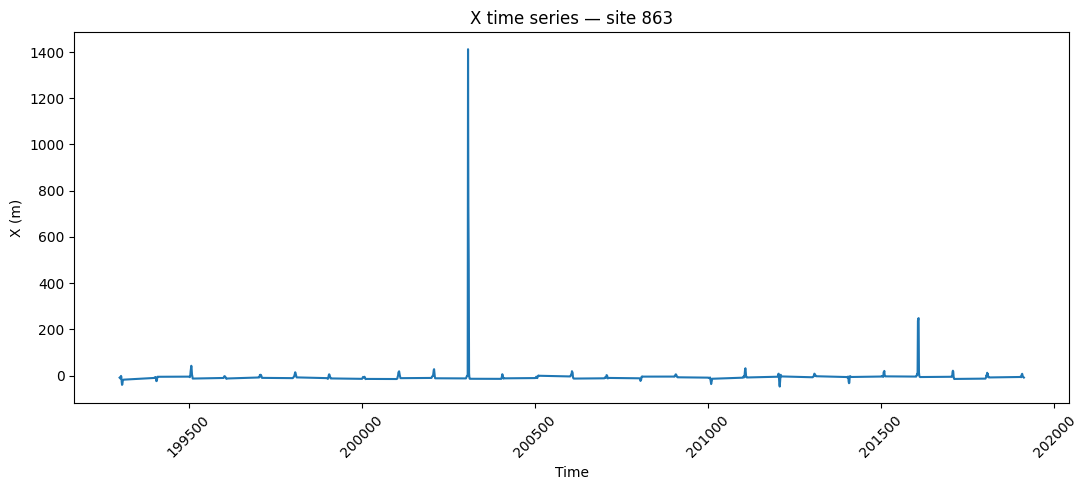

,Time,X_m
126,200307.0,1412.145630
127,200308.0,728.190002
128,200309.0,484.975037
281,201606.0,236.672897
282,201607.0,246.459610
283,201608.0,248.741089


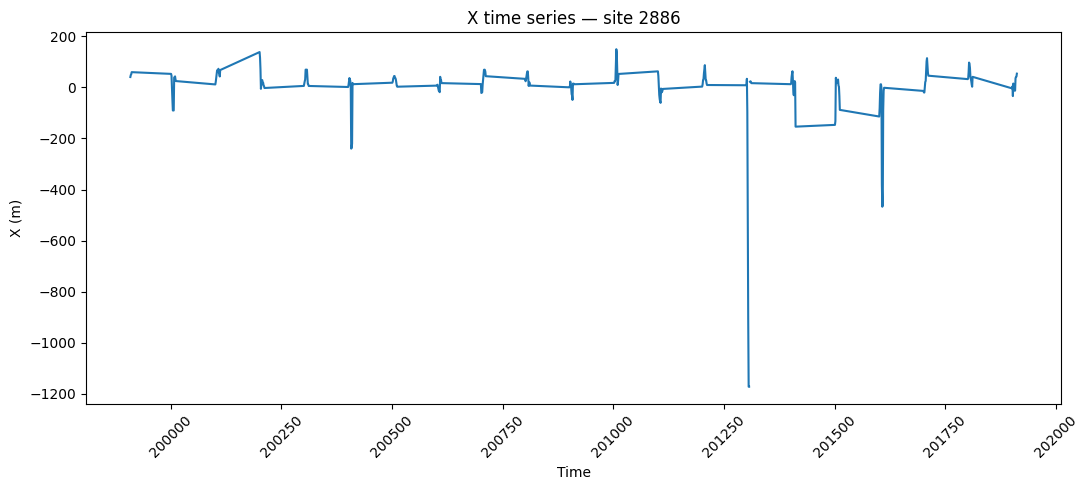

,Time,X_m
108,200201.0,138.421173
109,200202.0,116.200111
139,200408.0,-239.910797
140,200409.0,-236.871826
141,200410.0,-220.137070
210,201007.0,149.609390
211,201008.0,136.299026
243,201304.0,-494.832642
244,201305.0,-907.889343
245,201306.0,-1172.608521


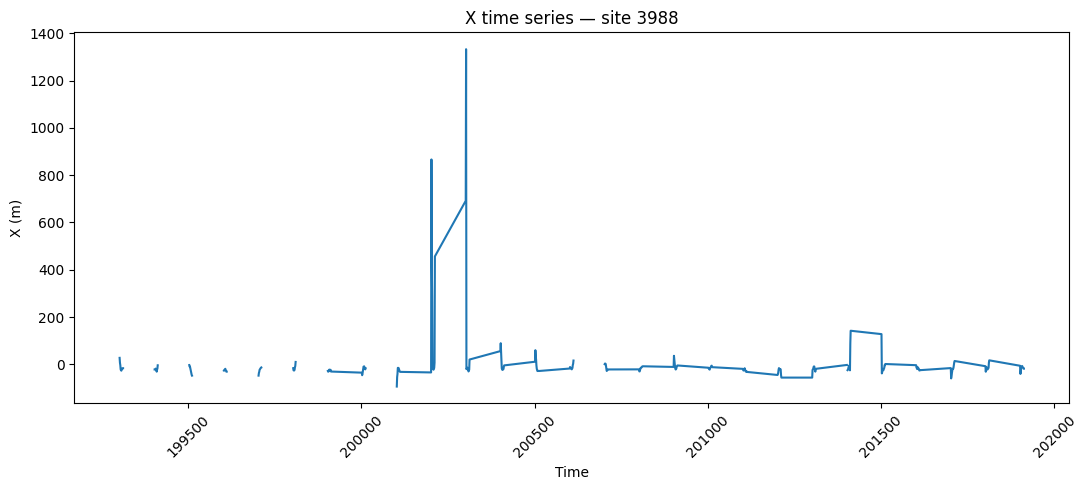

,Time,X_m
109,200202.0,866.411438
110,200203.0,431.128235
111,200204.0,286.033844
119,200212.0,456.538879
120,200301.0,691.672180
121,200302.0,1332.595947
263,201412.0,142.201248
264,201501.0,127.914093


In [11]:
selected_sites=[863,2886,3988]
time_values=np.asarray(ds["time"].values) if "time" in ds.coords else np.arange(ds.sizes[time_dim])
for i in selected_sites:
    if i>=ds.sizes[site_dim]: print("Site out of range:",i); continue
    series=np.asarray(ds["X"].isel({site_dim:i}).values,dtype=float)
    plt.figure(); plt.plot(time_values,series); plt.title(f"X time series — site {i}")
    plt.xlabel("Time"); plt.ylabel("X (m)"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    display(pd.DataFrame({"Time":time_values,"X_m":series}).query("X_m > 100 or X_m < -100"))

## 1.8 — Tunisia case-study candidate sites

In [12]:
tunisia_indices=[3142,3150,3155,3156,3158,3163,3164]
valid_tn=[i for i in tunisia_indices if i<ds.sizes[site_dim]]
tunisia_df=pd.DataFrame({"Site_Index":valid_tn,
 "Latitude":lat[valid_tn] if len(lat)==ds.sizes[site_dim] else np.nan,
 "Longitude":lon[valid_tn] if len(lon)==ds.sizes[site_dim] else np.nan})
for var in variables:
    da=ds[var]
    if da.ndim==2 and da.dims[0]==site_dim:
        tunisia_df[var+"_Valid_Months"]=[int(da.isel({site_dim:i}).notnull().sum()) for i in valid_tn]
display(tunisia_df.round(5))

,Site_Index,Latitude,Longitude,X_Valid_Months,River_drivers_Valid_Months,SLA_drivers_Valid_Months,Wave_Hs_drivers_Valid_Months,Wave_Tp_drivers_Valid_Months,Wave_Dir_drivers_Valid_Months
0,3142,37.23039,9.33164,324,319,324,324,324,324
1,3150,36.81125,11.05244,324,319,324,324,324,324
2,3155,35.06164,11.02119,324,0,324,324,324,324
3,3156,34.72247,10.75625,324,0,324,324,324,324
4,3158,34.29164,10.09706,324,319,324,324,324,324
5,3163,33.29953,11.24908,324,319,324,324,324,324
6,3164,33.20533,11.26744,324,319,324,324,324,324


## 1.9 — Plot Tunisia candidate sites

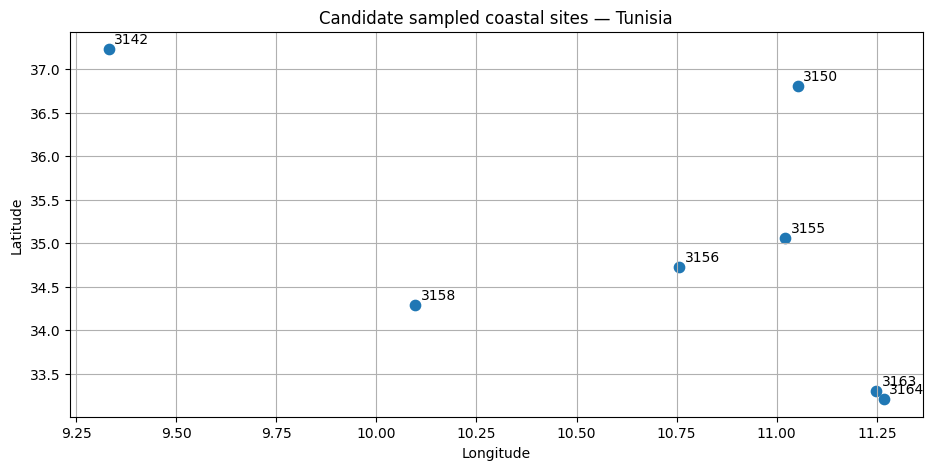

In [13]:
if tunisia_df["Latitude"].notna().all() and tunisia_df["Longitude"].notna().all():
    plt.figure(); plt.scatter(tunisia_df["Longitude"],tunisia_df["Latitude"],s=55)
    for _,r in tunisia_df.iterrows():
        plt.annotate(str(int(r["Site_Index"])),(r["Longitude"],r["Latitude"]),xytext=(4,4),textcoords="offset points")
    plt.title("Candidate sampled coastal sites — Tunisia"); plt.xlabel("Longitude"); plt.ylabel("Latitude")
    plt.grid(True); plt.show()
else: print("Coordinate arrays need verification against dataset documentation.")

# PHASE 2 — Data Cleaning & Preprocessing Preparation

## 2.1 — Detailed missing-values report

In [14]:
missing_rows=[]
for var in variables:
    a=np.asarray(ds[var].values); total=a.size; miss=int(np.isnan(a).sum())
    missing_rows.append({"Variable":var,"Total":total,"Missing":miss,"Valid":int(np.isfinite(a).sum()),
                         "Missing_Percent":round(100*miss/total,2)})
missing_df=pd.DataFrame(missing_rows); display(missing_df)

,Variable,Total,Missing,Valid,Missing_Percent
0,X,2864484,102727,2761757,3.59
1,River_drivers,2864484,428281,2436203,14.95
2,SLA_drivers,2864484,0,2864484,0.00
3,Wave_Hs_drivers,2864484,0,2864484,0.00
4,Wave_Tp_drivers,2864484,0,2864484,0.00
5,Wave_Dir_drivers,2864484,0,2864484,0.00


## 2.2 — Missing values by site

In [15]:
missing_site_rows=[]
for var in variables:
    da=ds[var]
    if da.ndim!=2: continue
    sd,td=da.dims
    counts=da.isnull().sum(dim=td).values
    for i,n in enumerate(counts):
        missing_site_rows.append({"Variable":var,"Site_Index":i,"Missing_Months":int(n)})
missing_sites_df=pd.DataFrame(missing_site_rows)
display(missing_sites_df.groupby("Variable").agg(
    Sites_With_Missing=("Missing_Months",lambda x:int((x>0).sum())),
    Sites_Without_Missing=("Missing_Months",lambda x:int((x==0).sum())),
    Max_Missing_Months=("Missing_Months","max"),
    Mean_Missing_Months=("Missing_Months","mean")).round(2).reset_index())

,Variable,Sites_With_Missing,Sites_Without_Missing,Max_Missing_Months,Mean_Missing_Months
0,River_drivers,8841,0,324,48.44
1,SLA_drivers,0,8841,0,0.00
2,Wave_Dir_drivers,0,8841,0,0.00
3,Wave_Hs_drivers,0,8841,0,0.00
4,Wave_Tp_drivers,0,8841,0,0.00
5,X,3482,5359,324,11.62


## 2.3 — Missing values across time

In [16]:
temporal_rows=[]
for var in variables:
    da=ds[var]
    if da.ndim!=2: continue
    sd,td=da.dims
    counts=da.isnull().sum(dim=sd).values
    for t,n in enumerate(counts):
        temporal_rows.append({"Variable":var,"Time_Index":t,"Missing_Sites":int(n)})
temporal_missing_df=pd.DataFrame(temporal_rows)
display(temporal_missing_df.groupby("Variable").agg(
    Months_With_Missing=("Missing_Sites",lambda x:int((x>0).sum())),
    Max_Missing_Sites=("Missing_Sites","max"),
    Mean_Missing_Sites=("Missing_Sites","mean")).round(2).reset_index())

,Variable,Months_With_Missing,Max_Missing_Sites,Mean_Missing_Sites
0,River_drivers,324,8841,1321.85
1,SLA_drivers,0,0,0.00
2,Wave_Dir_drivers,0,0,0.00
3,Wave_Hs_drivers,0,0,0.00
4,Wave_Tp_drivers,0,0,0.00
5,X,324,2002,317.06


## 2.4 — Visualize missing X values over time

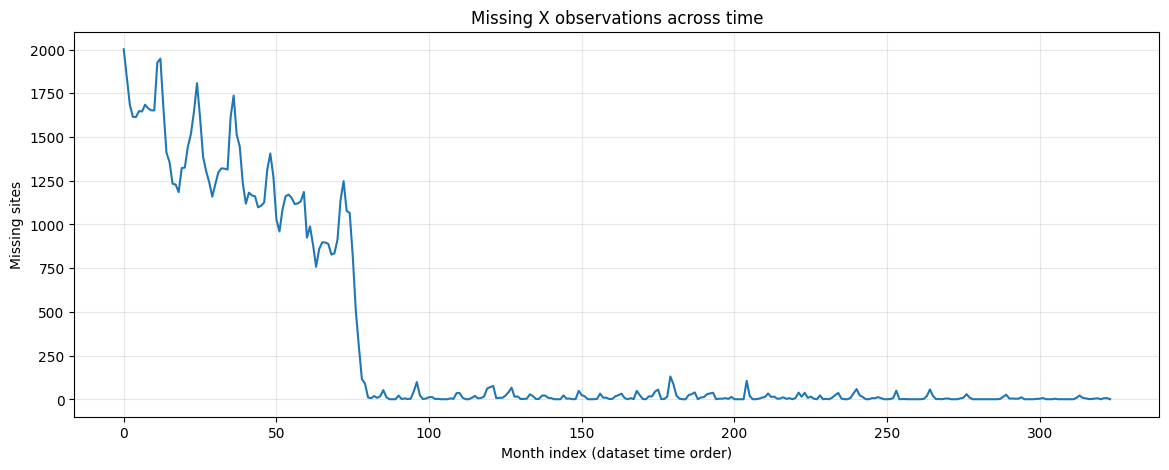

In [17]:
x_site_dim,x_time_dim=ds["X"].dims
x_missing_per_month=ds["X"].isnull().sum(dim=x_site_dim).values
plt.figure(figsize=(14,5)); plt.plot(x_missing_per_month)
plt.title("Missing X observations across time"); plt.xlabel("Month index (dataset time order)")
plt.ylabel("Missing sites"); plt.grid(alpha=.3); plt.show()

## 2.5 — IQR outlier screening for X (flag only)

In [18]:
q1,q3=np.percentile(x_valid,[25,75]); iqr=q3-q1
lower_bound=q1-1.5*iqr; upper_bound=q3+1.5*iqr
x_outliers=x_valid[(x_valid<lower_bound)|(x_valid>upper_bound)]
print(f"Q1={q1:.4f}; Q3={q3:.4f}; IQR={iqr:.4f}")
print(f"Lower bound={lower_bound:.4f}; Upper bound={upper_bound:.4f}")
print(f"Potential outliers={len(x_outliers):,} ({100*len(x_outliers)/len(x_valid):.2f}%)")
print("These are statistical flags, not confirmed errors.")

Q1=-4.7836; Q3=4.8687; IQR=9.6523
Lower bound=-19.2620; Upper bound=19.3472
Potential outliers=198,002 (7.17%)
These are statistical flags, not confirmed errors.


## 2.6 — Visualize IQR screening

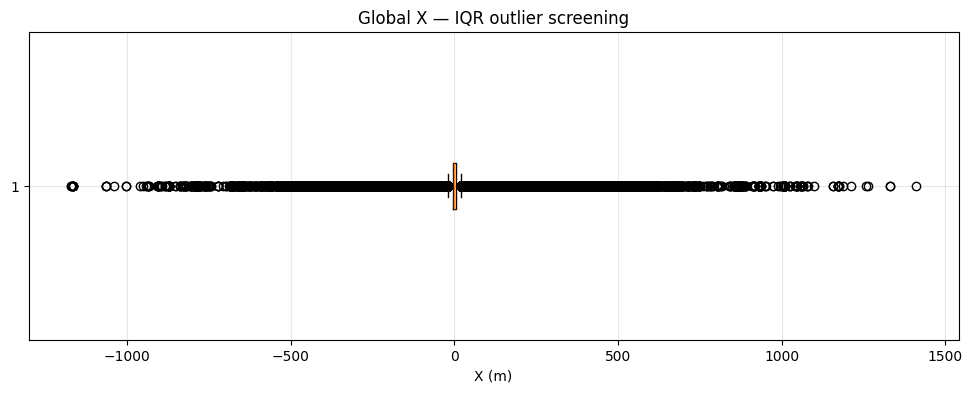

In [19]:
plt.figure(figsize=(12,4)); plt.boxplot(x_valid,vert=False)
plt.title("Global X — IQR outlier screening"); plt.xlabel("X (m)"); plt.grid(alpha=.3); plt.show()

## 2.7 — Create quality flags (no imputation, no deletion)

In [20]:
ds_clean=ds.copy(deep=False)
for var in variables:
    ds_clean[var+"_missing_flag"]=ds[var].isnull().astype("int8")
x_da=ds["X"]
flag=((x_da<lower_bound)|(x_da>upper_bound)) & x_da.notnull()
ds_clean["X_outlier_flag"]=flag.astype("int8")
print("Quality-flagged working copy created.")
print("Flagged X observations:",int(ds_clean["X_outlier_flag"].sum().values))

Quality-flagged working copy created.
Flagged X observations: 198002


## 2.8 — Validate original values

In [21]:
validation_rows=[]
for var in variables:
    original=np.asarray(ds[var].values); working=np.asarray(ds_clean[var].values)
    validation_rows.append({"Variable":var,"Same_Shape":original.shape==working.shape,
        "Same_Original_Values":np.array_equal(original,working,equal_nan=True),
        "Missing_Values":int(np.isnan(working).sum())})
validation_df=pd.DataFrame(validation_rows); display(validation_df)
assert validation_df["Same_Shape"].all()
assert validation_df["Same_Original_Values"].all()
print("Validation passed: original variables remain unchanged.")

,Variable,Same_Shape,Same_Original_Values,Missing_Values
0,X,True,True,102727
1,River_drivers,True,True,428281
2,SLA_drivers,True,True,0
3,Wave_Hs_drivers,True,True,0
4,Wave_Tp_drivers,True,True,0
5,Wave_Dir_drivers,True,True,0


Validation passed: original variables remain unchanged.


## 2.9 — Cleaning preparation summary

In [22]:
summary_rows=[]
for var in variables:
    a=np.asarray(ds_clean[var].values); total=a.size; valid=int(np.isfinite(a).sum()); miss=total-valid
    summary_rows.append({"Variable":var,"Total":total,"Valid":valid,"Missing":miss,
                         "Missing_Percent":round(100*miss/total,2)})
cleaning_summary_df=pd.DataFrame(summary_rows); display(cleaning_summary_df)

,Variable,Total,Valid,Missing,Missing_Percent
0,X,2864484,2761757,102727,3.59
1,River_drivers,2864484,2436203,428281,14.95
2,SLA_drivers,2864484,2864484,0,0.00
3,Wave_Hs_drivers,2864484,2864484,0,0.00
4,Wave_Tp_drivers,2864484,2864484,0,0.00
5,Wave_Dir_drivers,2864484,2864484,0,0.00


## 2.10 — Export working NetCDF and CSV reports

In [23]:
output_nc="CoastGuard_TN_Quality_Flagged_Working_Dataset.nc"
ds_clean.to_netcdf(output_nc)
csv_outputs={
 "phase1_global_quality.csv":quality_df,
 "phase1_site_availability.csv":availability_df,
 "phase1_extreme_sites.csv":extremes_df,
 "phase1_tunisia_sites.csv":tunisia_df,
 "phase2_missing_report.csv":missing_df,
 "phase2_missing_by_site.csv":missing_sites_df,
 "phase2_missing_by_time.csv":temporal_missing_df,
 "phase2_validation.csv":validation_df,
 "phase2_cleaning_summary.csv":cleaning_summary_df
}
for filename,frame in csv_outputs.items():
    frame.to_csv(filename,index=False)
print("Exported:",output_nc)
print("CSV reports:",list(csv_outputs))

Exported: CoastGuard_TN_Quality_Flagged_Working_Dataset.nc
CSV reports: ['phase1_global_quality.csv', 'phase1_site_availability.csv', 'phase1_extreme_sites.csv', 'phase1_tunisia_sites.csv', 'phase2_missing_report.csv', 'phase2_missing_by_site.csv', 'phase2_missing_by_time.csv', 'phase2_validation.csv', 'phase2_cleaning_summary.csv']


## 2.11 — Download exported files

In [24]:
from google.colab import files
for filename in [output_nc]+list(csv_outputs):
    if os.path.exists(filename):
        files.download(filename)
    else:
        print("Not found:",filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Phase 1 & 2 — Scientific notes and what comes next

**Completed in this notebook:** EDA, descriptive statistics, visual inspection, missingness analysis by variable/site/time, IQR screening, quality flags, validation, and export.

**Not performed yet:** final imputation, deletion/clipping of outliers, final ML training dataset, or model training.

**Next:** consult the dataset paper/ReadMe to verify units, aggregation, and coordinate pairing; decide missing-data treatment per variable and prediction task; then proceed to Feature Engineering and time-aware ML preparation.

Dataset DOI: https://doi.org/10.23708/YEEOOW

# PHASE 3 — Feature Engineering

This phase creates additional time-related and environmental features for later analysis and modelling.

**Important:** these are engineered features, not proof of causal relationships. Lag and rolling features are calculated separately within each site to avoid mixing observations from different coastal sites. Rolling and lag features use past observations only. Missing values created by lag/rolling operations are kept as missing; they are not filled automatically.

## 3.1 — Prepare time index

The dataset time coordinate is expected to be stored as `YYYYMM` integers (for example, `199301`). This cell parses it safely and checks the resulting date sequence.

In [33]:
# PHASE 3 — STEP 3.1
# Parse the YYYYMM time coordinate

raw_time = np.asarray(ds["time"].values)

time_text = pd.Series(raw_time).astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(6)
time_index = pd.to_datetime(time_text, format="%Y%m", errors="coerce")

if time_index.isna().any():
    raise ValueError("Some time values could not be parsed as YYYYMM. Inspect ds['time'] before continuing.")

time_features = pd.DataFrame({
    "Time": time_index,
    "Year": time_index.dt.year,
    "Month": time_index.dt.month,
    "Quarter": time_index.dt.quarter,
    "Season": time_index.dt.month.map({
        12: "Winter", 1: "Winter", 2: "Winter",
        3: "Spring", 4: "Spring", 5: "Spring",
        6: "Summer", 7: "Summer", 8: "Summer",
        9: "Autumn", 10: "Autumn", 11: "Autumn"
    })
})

display(time_features.head(12))
print("Number of time observations:", len(time_features))
print("First month:", time_index.min())
print("Last month:", time_index.max())
print("Time coordinate is strictly increasing:", time_index.is_monotonic_increasing)

,Time,Year,Month,Quarter,Season
0,1993-01-01,1993,1,1,Winter
1,1993-02-01,1993,2,1,Winter
2,1993-03-01,1993,3,1,Spring
3,1993-04-01,1993,4,2,Spring
4,1993-05-01,1993,5,2,Spring
5,1993-06-01,1993,6,2,Summer
6,1993-07-01,1993,7,3,Summer
7,1993-08-01,1993,8,3,Summer
8,1993-09-01,1993,9,3,Autumn
9,1993-10-01,1993,10,4,Autumn


Number of time observations: 324
First month: 1993-01-01 00:00:00
Last month: 2019-12-01 00:00:00
Time coordinate is strictly increasing: True


## 3.2 — Encode seasonal patterns

Month and season are cyclical: December is close to January. Sine/cosine encoding represents this circular relationship more appropriately than treating month as a simple linear number.

In [34]:
# PHASE 3 — STEP 3.2
# Cyclical month features

time_features["Month_Sin"] = np.sin(2 * np.pi * time_features["Month"] / 12)
time_features["Month_Cos"] = np.cos(2 * np.pi * time_features["Month"] / 12)

display(time_features.head(12))

,Time,Year,Month,Quarter,Season,Month_Sin,Month_Cos
0,1993-01-01,1993,1,1,Winter,5.000000e-01,8.660254e-01
1,1993-02-01,1993,2,1,Winter,8.660254e-01,5.000000e-01
2,1993-03-01,1993,3,1,Spring,1.000000e+00,6.123234e-17
3,1993-04-01,1993,4,2,Spring,8.660254e-01,-5.000000e-01
4,1993-05-01,1993,5,2,Spring,5.000000e-01,-8.660254e-01
5,1993-06-01,1993,6,2,Summer,1.224647e-16,-1.000000e+00
6,1993-07-01,1993,7,3,Summer,-5.000000e-01,-8.660254e-01
7,1993-08-01,1993,8,3,Summer,-8.660254e-01,-5.000000e-01
8,1993-09-01,1993,9,3,Autumn,-1.000000e+00,-1.836970e-16
9,1993-10-01,1993,10,4,Autumn,-8.660254e-01,5.000000e-01


## 3.3 — Build a site-by-time feature table

We create a long-format table for the target `X` and environmental drivers. Each row represents one site at one month. Latitude/longitude are attached only when their arrays match the site dimension length. This can be memory-intensive, so monitor Colab RAM.

In [35]:
# PHASE 3 — STEP 3.3
# Convert selected 2D variables into a long-format table

required_for_table = ["X", "SLA_drivers", "Wave_Hs_drivers", "Wave_Tp_drivers", "Wave_Dir_drivers"]
available_for_table = [v for v in required_for_table if v in ds.data_vars]

if "X" not in available_for_table:
    raise KeyError("X is required as the target variable.")

site_dim, time_dim = ds["X"].dims
n_sites = ds.sizes[site_dim]
n_times = ds.sizes[time_dim]

if n_times != len(time_features):
    raise ValueError("Time feature count does not match the X time dimension.")

feature_data = {
    "Site_Index": np.repeat(np.arange(n_sites), n_times),
    "Time_Index": np.tile(np.arange(n_times), n_sites),
    "Date": np.tile(time_features["Time"].to_numpy(), n_sites),
    "Year": np.tile(time_features["Year"].to_numpy(), n_sites),
    "Month": np.tile(time_features["Month"].to_numpy(), n_sites),
    "Quarter": np.tile(time_features["Quarter"].to_numpy(), n_sites),
    "Season": np.tile(time_features["Season"].to_numpy(), n_sites),
    "Month_Sin": np.tile(time_features["Month_Sin"].to_numpy(), n_sites),
    "Month_Cos": np.tile(time_features["Month_Cos"].to_numpy(), n_sites),
}

for var in available_for_table:
    da = ds[var]
    if da.ndim != 2 or da.dims != ds["X"].dims:
        raise ValueError(f"{var} dimensions {da.dims} do not match X dimensions {ds['X'].dims}.")
    feature_data[var] = np.asarray(da.values).reshape(-1)

if "lat" in ds and ds["lat"].size == n_sites:
    feature_data["Latitude"] = np.repeat(np.asarray(ds["lat"].values), n_times)
if "lon" in ds and ds["lon"].size == n_sites:
    feature_data["Longitude"] = np.repeat(np.asarray(ds["lon"].values), n_times)

features_df = pd.DataFrame(feature_data)
print("Feature table shape:", features_df.shape)
display(features_df.head())
print("Rows expected (sites × months):", n_sites * n_times)

Feature table shape: (2864484, 16)


,Site_Index,Time_Index,Date,Year,Month,Quarter,Season,Month_Sin,Month_Cos,X,SLA_drivers,Wave_Hs_drivers,Wave_Tp_drivers,Wave_Dir_drivers,Latitude,Longitude
0,0,0,1993-01-01,1993,1,1,Winter,0.500000,8.660254e-01,NaN,0.074361,2.290781,10.078651,146.692854,59.993333,170.150722
1,0,1,1993-02-01,1993,2,1,Winter,0.866025,5.000000e-01,NaN,0.051143,3.372156,10.279130,103.426199,59.993333,170.150722
2,0,2,1993-03-01,1993,3,1,Spring,1.000000,6.123234e-17,NaN,0.032826,2.551653,8.799234,100.936625,59.993333,170.150722
3,0,3,1993-04-01,1993,4,2,Spring,0.866025,-5.000000e-01,NaN,0.030158,1.420007,9.843243,126.323052,59.993333,170.150722
4,0,4,1993-05-01,1993,5,2,Spring,0.500000,-8.660254e-01,NaN,-0.011360,1.307042,9.337730,134.283944,59.993333,170.150722


Rows expected (sites × months): 2864484


## 3.4 — Add river driver carefully

River discharge has missing values at some sites and months. We include it as a feature if present, but do not replace missing values with zero. The later modelling phase will decide whether to use a river-inclusive subset or a separate model.

In [36]:
# PHASE 3 — STEP 3.4
if "River_drivers" in ds.data_vars:
    river_da = ds["River_drivers"]
    if river_da.dims != ds["X"].dims:
        raise ValueError("River_drivers dimensions do not match X.")
    features_df["River_drivers"] = np.asarray(river_da.values).reshape(-1)
    print("River driver added. Missing values preserved:",
          int(features_df["River_drivers"].isna().sum()))
else:
    print("River_drivers is not present in this dataset.")

River driver added. Missing values preserved: 428281


## 3.5 — Create past-value lag features per site

Lag 1 and Lag 3 mean the value one month and three months earlier. We group by site before shifting, so a site's history never leaks into another site's rows. No future values are used.

In [37]:
# PHASE 3 — STEP 3.5
# Create lag features separately for each site

lag_variables = [
    v for v in ["X", "SLA_drivers", "Wave_Hs_drivers", "Wave_Tp_drivers", "Wave_Dir_drivers"]
    if v in features_df.columns
]

features_df = features_df.sort_values(["Site_Index", "Time_Index"]).reset_index(drop=True)

for var in lag_variables:
    features_df[f"{var}_Lag1"] = features_df.groupby("Site_Index")[var].shift(1)
    features_df[f"{var}_Lag3"] = features_df.groupby("Site_Index")[var].shift(3)

display(features_df[["Site_Index", "Date"] + lag_variables[:2] +
                    [f"{v}_Lag1" for v in lag_variables[:2]]].head(10))

,Site_Index,Date,X,SLA_drivers,X_Lag1,SLA_drivers_Lag1
0,0,1993-01-01,NaN,0.074361,NaN,NaN
1,0,1993-02-01,NaN,0.051143,NaN,0.074361
2,0,1993-03-01,NaN,0.032826,NaN,0.051143
3,0,1993-04-01,NaN,0.030158,NaN,0.032826
4,0,1993-05-01,NaN,-0.011360,NaN,0.030158
5,0,1993-06-01,NaN,-0.027222,NaN,-0.011360
6,0,1993-07-01,NaN,-0.029941,NaN,-0.027222
7,0,1993-08-01,NaN,-0.014608,NaN,-0.029941
8,0,1993-09-01,NaN,0.023448,NaN,-0.014608
9,0,1993-10-01,NaN,0.040876,NaN,0.023448


## 3.6 — Create rolling statistics using past observations only

A three-month rolling mean is calculated from the previous three months, excluding the current month (`shift(1)` first). This avoids using the current target month when creating historical predictors.

In [38]:
# PHASE 3 — STEP 3.6
rolling_variables = [
    v for v in ["SLA_drivers", "Wave_Hs_drivers", "Wave_Tp_drivers", "Wave_Dir_drivers"]
    if v in features_df.columns
]

for var in rolling_variables:
    features_df[f"{var}_RollingMean3_Past"] = (
        features_df.groupby("Site_Index")[var]
        .transform(lambda s: s.shift(1).rolling(window=3, min_periods=3).mean())
    )

display(features_df[["Site_Index", "Date"] +
                    [f"{v}_RollingMean3_Past" for v in rolling_variables]].head(10))

,Site_Index,Date,SLA_drivers_RollingMean3_Past,Wave_Hs_drivers_RollingMean3_Past,Wave_Tp_drivers_RollingMean3_Past,Wave_Dir_drivers_RollingMean3_Past
0,0,1993-01-01,NaN,NaN,NaN,NaN
1,0,1993-02-01,NaN,NaN,NaN,NaN
2,0,1993-03-01,NaN,NaN,NaN,NaN
3,0,1993-04-01,0.052777,2.738197,9.719005,117.018559
4,0,1993-05-01,0.038042,2.447938,9.640536,110.228625
5,0,1993-06-01,0.017208,1.759567,9.326735,120.514540
6,0,1993-07-01,-0.002808,1.345384,9.671348,131.136236
7,0,1993-08-01,-0.022841,1.259532,9.205538,138.748549
8,0,1993-09-01,-0.023924,1.282843,8.959263,150.245315
9,0,1993-10-01,-0.007034,1.374297,8.537871,150.012858


## 3.7 — Add simple environmental interaction features

These products can help a model represent combined environmental conditions. They are candidate features only; their usefulness must be tested during model evaluation.

In [39]:
# PHASE 3 — STEP 3.7
if "SLA_drivers" in features_df.columns and "Wave_Hs_drivers" in features_df.columns:
    features_df["SLA_x_WaveHs"] = (
        features_df["SLA_drivers"] * features_df["Wave_Hs_drivers"]
    )

if "Wave_Hs_drivers" in features_df.columns and "Wave_Tp_drivers" in features_df.columns:
    features_df["Wave_Energy_Proxy"] = (
        features_df["Wave_Hs_drivers"] ** 2 * features_df["Wave_Tp_drivers"]
    )

display(features_df.head())

,Site_Index,Time_Index,Date,Year,Month,Quarter,Season,Month_Sin,Month_Cos,X,SLA_drivers,Wave_Hs_drivers,Wave_Tp_drivers,Wave_Dir_drivers,Latitude,Longitude,River_drivers,X_Lag1,X_Lag3,SLA_drivers_Lag1,SLA_drivers_Lag3,Wave_Hs_drivers_Lag1,Wave_Hs_drivers_Lag3,Wave_Tp_drivers_Lag1,Wave_Tp_drivers_Lag3,Wave_Dir_drivers_Lag1,Wave_Dir_drivers_Lag3,SLA_drivers_RollingMean3_Past,Wave_Hs_drivers_RollingMean3_Past,Wave_Tp_drivers_RollingMean3_Past,Wave_Dir_drivers_RollingMean3_Past,SLA_x_WaveHs,Wave_Energy_Proxy
0,0,0,1993-01-01,1993,1,1,Winter,0.500000,8.660254e-01,NaN,0.074361,2.290781,10.078651,146.692854,59.993333,170.150722,3.020516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.170344,52.889507
1,0,1,1993-02-01,1993,2,1,Winter,0.866025,5.000000e-01,NaN,0.051143,3.372156,10.279130,103.426199,59.993333,170.150722,2.896931,NaN,NaN,0.074361,NaN,2.290781,NaN,10.078651,NaN,146.692854,NaN,NaN,NaN,NaN,NaN,0.172461,116.888494
2,0,2,1993-03-01,1993,3,1,Spring,1.000000,6.123234e-17,NaN,0.032826,2.551653,8.799234,100.936625,59.993333,170.150722,2.687171,NaN,NaN,0.051143,NaN,3.372156,NaN,10.279130,NaN,103.426199,NaN,NaN,NaN,NaN,NaN,0.083761,57.291205
3,0,3,1993-04-01,1993,4,2,Spring,0.866025,-5.000000e-01,NaN,0.030158,1.420007,9.843243,126.323052,59.993333,170.150722,2.601672,NaN,NaN,0.032826,0.074361,2.551653,2.290781,8.799234,10.078651,100.936625,146.692854,0.052777,2.738197,9.719005,117.018559,0.042824,19.848097
4,0,4,1993-05-01,1993,5,2,Spring,0.500000,-8.660254e-01,NaN,-0.011360,1.307042,9.337730,134.283944,59.993333,170.150722,43.069808,NaN,NaN,0.030158,0.051143,1.420007,3.372156,9.843243,10.279130,126.323052,103.426199,0.038042,2.447938,9.640536,110.228625,-0.014848,15.952192


## 3.8 — Validate engineered features

Check row count, duplicate site-month keys, and missingness introduced by lag/rolling features. Missing lag/rolling values at the start of each site's time series are expected.

In [40]:
# PHASE 3 — STEP 3.8
expected_rows = n_sites * n_times
duplicate_keys = int(features_df.duplicated(["Site_Index", "Time_Index"]).sum())

engineered_columns = [
    c for c in features_df.columns
    if "_Lag" in c or "_RollingMean" in c
]

feature_validation = pd.DataFrame({
    "Metric": [
        "Expected rows (sites × months)",
        "Actual rows",
        "Duplicate site-month keys",
        "Number of columns",
        "Engineered lag/rolling columns"
    ],
    "Value": [
        expected_rows,
        len(features_df),
        duplicate_keys,
        len(features_df.columns),
        len(engineered_columns)
    ]
})
display(feature_validation)

assert len(features_df) == expected_rows, "Unexpected number of rows."
assert duplicate_keys == 0, "Duplicate site-month records found."
print("Feature table structural validation passed.")

,Metric,Value
0,Expected rows (sites × months),2864484
1,Actual rows,2864484
2,Duplicate site-month keys,0
3,Number of columns,33
4,Engineered lag/rolling columns,14


Feature table structural validation passed.


## 3.9 — Review feature missingness

This report helps decide which features can be used in a modelling experiment. Do not automatically drop all rows with missing values; that decision depends on the chosen target, predictors, and evaluation design.

In [41]:
feature_missing_report = pd.DataFrame({
    "Feature": features_df.columns,
    "Missing_Count": [int(features_df[c].isna().sum()) for c in features_df.columns],
    "Missing_Percent": [
        round(100 * features_df[c].isna().mean(), 2) for c in features_df.columns
    ]
}).sort_values("Missing_Percent", ascending=False)

display(feature_missing_report)

,Feature,Missing_Count,Missing_Percent
16,River_drivers,428281,14.95
18,X_Lag3,129235,4.51
17,X_Lag1,111567,3.89
9,X,102727,3.59
26,Wave_Dir_drivers_Lag3,26523,0.93
22,Wave_Hs_drivers_Lag3,26523,0.93
20,SLA_drivers_Lag3,26523,0.93
28,Wave_Hs_drivers_RollingMean3_Past,26523,0.93
24,Wave_Tp_drivers_Lag3,26523,0.93
29,Wave_Tp_drivers_RollingMean3_Past,26523,0.93


## 3.10 — Export the engineered feature table

This CSV can be large. If memory or download limits occur, we can export selected columns or partition by site/year in a later step.

In [42]:
features_output = "CoastGuard_TN_Engineered_Features.csv"
features_df.to_csv(features_output, index=False)
print("Exported:", features_output)
print("File size (MB):", round(os.path.getsize(features_output) / (1024 ** 2), 2))

from google.colab import files
files.download(features_output)

Exported: CoastGuard_TN_Engineered_Features.csv
File size (MB): 1387.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# PHASE 4 — Machine Learning: Modelling & Evaluation

**Objective:** estimate the monthly detrended waterline position `X` using information available for the same month and the site's past history.

**Important scientific distinction:** because some predictors (for example, monthly wave and sea-level drivers) are measured for the target month, this first experiment is a *monthly estimation/nowcasting model*, not yet a genuine future forecast. A future-forecasting experiment must use only predictors that would be available before the forecast month.

We use a chronological train/test split, keep the original target values, do not delete outliers, and do not replace missing river discharge with zero. River discharge is excluded from this first baseline because it has substantial missingness; it can be tested later as a separate experiment.

## 4.1 — Install and import Machine Learning libraries

Run this cell once. The notebook must already have completed Phases 1–3 so that `features_df` exists.

In [43]:
!pip -q install scikit-learn joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

print("scikit-learn is ready.")
print("Feature table:", features_df.shape)

scikit-learn is ready.
Feature table: (2864484, 33)


## 4.2 — Validate the modelling table

We verify the target, dates, and engineered features before training. This step does not modify the source NetCDF dataset.

In [44]:
required_columns = ["X", "Date", "Site_Index", "Time_Index"]
missing_required = [c for c in required_columns if c not in features_df.columns]

if missing_required:
    raise KeyError(f"Required columns are missing: {missing_required}")

features_df["Date"] = pd.to_datetime(features_df["Date"], errors="coerce")

print("Rows:", len(features_df))
print("Sites:", features_df["Site_Index"].nunique())
print("Date range:", features_df["Date"].min(), "to", features_df["Date"].max())
print("Target missing:", int(features_df["X"].isna().sum()))
display(features_df[required_columns].head())

Rows: 2864484
Sites: 8841
Date range: 1993-01-01 00:00:00 to 2019-12-01 00:00:00
Target missing: 102727


,X,Date,Site_Index,Time_Index
0,NaN,1993-01-01,0,0
1,NaN,1993-02-01,0,1
2,NaN,1993-03-01,0,2
3,NaN,1993-04-01,0,3
4,NaN,1993-05-01,0,4


## 4.3 — Select candidate predictors

The target is the current month's `X`. We exclude current `X`, identifiers, and the river driver from this first baseline. Candidate predictors include past waterline values, environmental drivers, past-only rolling statistics, calendar seasonality, and site coordinates when available.

We do not use `Site_Index` as a numeric predictor because its numeric order has no physical meaning.

In [45]:
candidate_features = [
    "X_Lag1", "X_Lag3",
    "SLA_drivers", "Wave_Hs_drivers", "Wave_Tp_drivers", "Wave_Dir_drivers",
    "SLA_drivers_Lag1", "SLA_drivers_Lag3",
    "Wave_Hs_drivers_Lag1", "Wave_Hs_drivers_Lag3",
    "Wave_Tp_drivers_Lag1", "Wave_Tp_drivers_Lag3",
    "Wave_Dir_drivers_Lag1", "Wave_Dir_drivers_Lag3",
    "SLA_drivers_RollingMean3_Past",
    "Wave_Hs_drivers_RollingMean3_Past",
    "Wave_Tp_drivers_RollingMean3_Past",
    "Wave_Dir_drivers_RollingMean3_Past",
    "SLA_x_WaveHs", "Wave_Energy_Proxy",
    "Month_Sin", "Month_Cos", "Latitude", "Longitude"
]

feature_columns = [
    c for c in candidate_features
    if c in features_df.columns and pd.api.types.is_numeric_dtype(features_df[c])
]

if not feature_columns:
    raise ValueError("No candidate predictor columns were found. Check Phase 3 outputs.")

print("Selected predictors:", len(feature_columns))
print(feature_columns)
print("River driver excluded from this baseline:", "River_drivers" in features_df.columns)

Selected predictors: 24
['X_Lag1', 'X_Lag3', 'SLA_drivers', 'Wave_Hs_drivers', 'Wave_Tp_drivers', 'Wave_Dir_drivers', 'SLA_drivers_Lag1', 'SLA_drivers_Lag3', 'Wave_Hs_drivers_Lag1', 'Wave_Hs_drivers_Lag3', 'Wave_Tp_drivers_Lag1', 'Wave_Tp_drivers_Lag3', 'Wave_Dir_drivers_Lag1', 'Wave_Dir_drivers_Lag3', 'SLA_drivers_RollingMean3_Past', 'Wave_Hs_drivers_RollingMean3_Past', 'Wave_Tp_drivers_RollingMean3_Past', 'Wave_Dir_drivers_RollingMean3_Past', 'SLA_x_WaveHs', 'Wave_Energy_Proxy', 'Month_Sin', 'Month_Cos', 'Latitude', 'Longitude']
River driver excluded from this baseline: True


## 4.4 — Chronological Train/Test split

The split is based on **dates**, not random rows: the earliest 80% of distinct months are used for training and the latest 20% for testing. This reduces temporal leakage.

Rows with missing target values are excluded. Predictor missing values are handled inside each model's pipeline; imputation is fitted on training data only.

In [46]:
valid = features_df["Date"].notna() & features_df["X"].notna()
model_df = features_df.loc[valid, ["Date", "X"] + feature_columns].copy()

unique_dates = np.sort(model_df["Date"].unique())
if len(unique_dates) < 5:
    raise ValueError("Not enough distinct dates for a chronological train/test split.")

split_position = int(len(unique_dates) * 0.80)
split_position = min(max(split_position, 1), len(unique_dates) - 1)
split_date = pd.Timestamp(unique_dates[split_position])

train_df = model_df[model_df["Date"] < split_date].copy()
test_df = model_df[model_df["Date"] >= split_date].copy()

print("Training period:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Testing period:", test_df["Date"].min(), "to", test_df["Date"].max())
print("Train rows:", len(train_df), "| Test rows:", len(test_df))
print("Split date:", split_date)

if train_df.empty or test_df.empty:
    raise ValueError("Train or test set is empty. Recheck the date split.")

Training period: 1993-01-01 00:00:00 to 2014-07-01 00:00:00
Testing period: 2014-08-01 00:00:00 to 2019-12-01 00:00:00
Train rows: 2187461 | Test rows: 574296
Split date: 2014-08-01 00:00:00


## 4.5 — Create manageable modelling samples

The full feature table can contain millions of rows. To keep Colab memory and runtime manageable, this baseline samples up to 250,000 training rows and 75,000 test rows. Sampling is reproducible. The chronological boundary remains unchanged.

For a final scientific report, repeat the experiment with larger samples or full data if computing resources allow.

In [47]:
MAX_TRAIN_ROWS = 250_000
MAX_TEST_ROWS = 75_000
RANDOM_STATE = 42

if len(train_df) > MAX_TRAIN_ROWS:
    train_sample = train_df.sample(n=MAX_TRAIN_ROWS, random_state=RANDOM_STATE)
else:
    train_sample = train_df.copy()

if len(test_df) > MAX_TEST_ROWS:
    test_sample = test_df.sample(n=MAX_TEST_ROWS, random_state=RANDOM_STATE)
else:
    test_sample = test_df.copy()

X_train = train_sample[feature_columns]
y_train = train_sample["X"].astype(float)
X_test = test_sample[feature_columns]
y_test = test_sample["X"].astype(float)

print("Final training sample:", X_train.shape)
print("Final test sample:", X_test.shape)
print("Missing predictor values in train:", int(X_train.isna().sum().sum()))

Final training sample: (250000, 24)
Final test sample: (75000, 24)
Missing predictor values in train: 29383


## 4.6 — Train Model 1: Ridge Regression

Ridge is a regularized linear model. Median imputation and standardization are fitted using the training sample only.

In [48]:
ridge_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

print("Ridge training completed.")

Ridge training completed.


## 4.7 — Train Model 2: Histogram-based Gradient Boosting

This tree-based model can learn nonlinear relationships between environmental drivers and waterline position. Missing values are imputed within the pipeline using training data only.

In [49]:
boosting_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ))
])

boosting_model.fit(X_train, y_train)
boosting_predictions = boosting_model.predict(X_test)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


## 4.8 — Evaluate and compare models

- **MAE:** average absolute prediction error, in the target's unit (metres if the dataset documentation confirms that unit).
- **RMSE:** gives more weight to large errors.
- **R²:** proportion of target variance explained relative to a mean-baseline reference; it can be negative on unseen data.

These scores describe this sampled chronological test set, not guaranteed performance everywhere along the coast.

In [50]:
def regression_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results_df = pd.DataFrame([
    regression_metrics(y_test, ridge_predictions, "Ridge Regression"),
    regression_metrics(y_test, boosting_predictions, "Histogram Gradient Boosting")
]).sort_values("RMSE").reset_index(drop=True)

display(results_df)
best_model_name = results_df.loc[0, "Model"]
print("Best model by test RMSE:", best_model_name)

,Model,MAE,RMSE,R2
0,Ridge Regression,4.465373,12.220266,0.665639
1,Histogram Gradient Boosting,4.651976,15.487014,0.462981


Best model by test RMSE: Ridge Regression


## 4.9 — Visualize actual vs predicted values

The scatter plot uses a subset of test observations for readability. Points closer to the diagonal represent more accurate estimates.

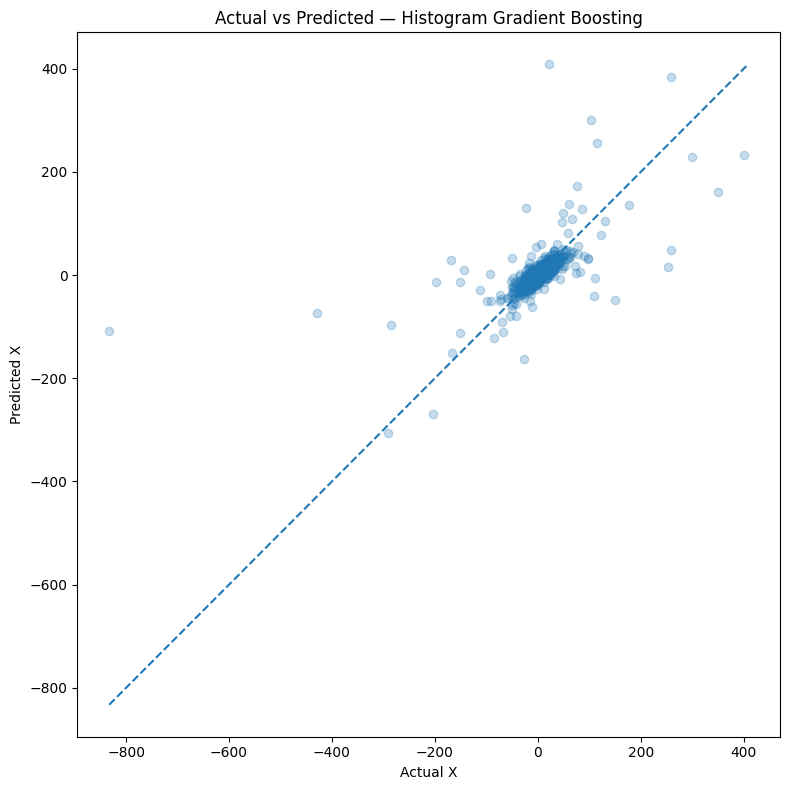

,Date,Actual_X,Ridge_Predicted_X,Boosting_Predicted_X
0,2016-02-01,2.355848,6.910949,8.174776
1,2015-09-01,-1.390257,-2.257978,-2.672269
2,2018-07-01,3.198914,0.403025,0.916457
3,2018-05-01,0.648884,-0.820603,-1.040978
4,2017-04-01,3.563544,3.594672,4.163638


In [51]:
predictions_df = pd.DataFrame({
    "Date": test_sample["Date"].to_numpy(),
    "Actual_X": y_test.to_numpy(),
    "Ridge_Predicted_X": ridge_predictions,
    "Boosting_Predicted_X": boosting_predictions
})

plot_n = min(5000, len(predictions_df))
plot_df = predictions_df.sample(n=plot_n, random_state=RANDOM_STATE) if plot_n else predictions_df

plt.figure(figsize=(8, 8))
plt.scatter(plot_df["Actual_X"], plot_df["Boosting_Predicted_X"], alpha=0.25)
limits = [
    min(plot_df["Actual_X"].min(), plot_df["Boosting_Predicted_X"].min()),
    max(plot_df["Actual_X"].max(), plot_df["Boosting_Predicted_X"].max())
]
plt.plot(limits, limits, linestyle="--")
plt.xlabel("Actual X")
plt.ylabel("Predicted X")
plt.title("Actual vs Predicted — Histogram Gradient Boosting")
plt.tight_layout()
plt.show()

display(predictions_df.head())

## 4.10 — Residual analysis

Residual = actual value − predicted value. A residual pattern may reveal systematic bias or groups of difficult observations. This is a diagnostic, not proof that model assumptions are satisfied.

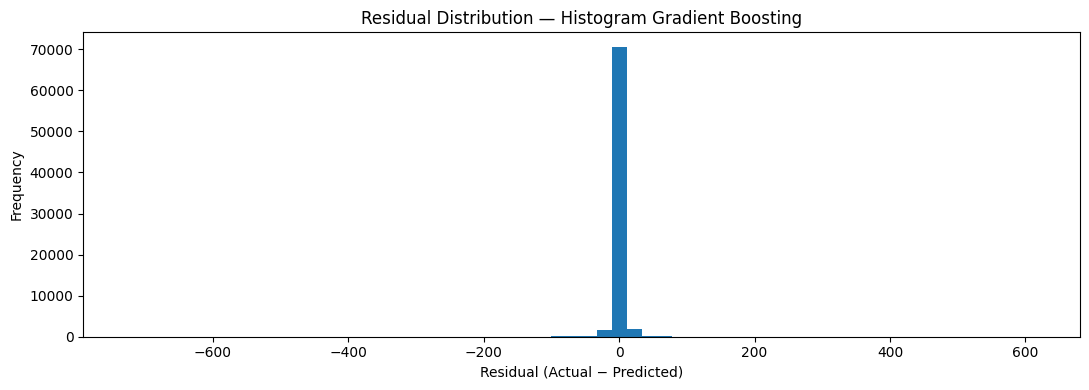

count    75000.000000
mean         0.430454
std         15.481134
min       -724.751243
25%         -1.669845
50%          0.561888
75%          2.843133
max        613.641874
Name: Boosting_Residual, dtype: float64


In [52]:
predictions_df["Boosting_Residual"] = (
    predictions_df["Actual_X"] - predictions_df["Boosting_Predicted_X"]
)

plt.figure(figsize=(11, 4))
plt.hist(predictions_df["Boosting_Residual"].dropna(), bins=60)
plt.xlabel("Residual (Actual − Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution — Histogram Gradient Boosting")
plt.tight_layout()
plt.show()

print(predictions_df["Boosting_Residual"].describe())

## 4.11 — Save evaluation outputs and trained baseline models

The CSV files contain the measured test predictions and model metrics. The joblib files preserve the fitted pipelines. Keep the original NetCDF dataset unchanged.

In [53]:
metrics_file = "CoastGuard_TN_Phase4_Model_Comparison.csv"
predictions_file = "CoastGuard_TN_Phase4_Test_Predictions.csv"

results_df.to_csv(metrics_file, index=False)
predictions_df.to_csv(predictions_file, index=False)

joblib.dump(ridge_model, "CoastGuard_TN_Ridge_Model.joblib")
joblib.dump(boosting_model, "CoastGuard_TN_HistGradientBoosting_Model.joblib")

print("Saved:", metrics_file)
print("Saved:", predictions_file)
print("Saved both fitted model pipelines.")

Saved: CoastGuard_TN_Phase4_Model_Comparison.csv
Saved: CoastGuard_TN_Phase4_Test_Predictions.csv
Saved both fitted model pipelines.


## 4.12 — Download Phase 4 outputs

Run this cell in Google Colab to download the evaluation files and fitted models.

In [54]:
from google.colab import files

phase4_outputs = [
    "CoastGuard_TN_Phase4_Model_Comparison.csv",
    "CoastGuard_TN_Phase4_Test_Predictions.csv",
    "CoastGuard_TN_Ridge_Model.joblib",
    "CoastGuard_TN_HistGradientBoosting_Model.joblib"
]

for filename in phase4_outputs:
    if os.path.exists(filename):
        files.download(filename)
    else:
        print("Not found:", filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 4 — Scientific interpretation and limitations

1. This is the first baseline modelling experiment; results must be inspected after execution.
2. The split is chronological, but test rows are sampled from the later period for computational efficiency.
3. Same-month environmental drivers make this an estimation/nowcasting task. A genuine forecast requires predictors available before the forecast date and a redesigned evaluation.
4. River discharge is excluded from this baseline because of its missingness. Do not fill missing river values with zero; evaluate a separate river-aware strategy later.
5. The target `X` is the dataset's detrended waterline position. Do not interpret it automatically as absolute shoreline movement without consulting the dataset documentation.
6. Extreme values are retained. Investigate their physical meaning and influence before deciding on any filtering.
7. A global random sample may under-represent some regions. Later validation should include spatial holdouts and a dedicated Tunisia case-study evaluation.
8. Compare models using MAE, RMSE, and R² on the same test sample. Do not report performance numbers until the notebook has actually run.

**Next research steps:** spatial validation, Tunisia-specific evaluation, river-driver experiments, hyperparameter tuning, and a strictly future-oriented forecasting setup.

# CoastGuard TN — Phase 5: Global Geospatial Analysis

**Project:** Global coastal monitoring, with Tunisia as a detailed case study.

## Objectives
1. Prepare geographic coordinates for the dataset's coastal sites.
2. Visualize the global distribution of sites.
3. Estimate temporal linear trends in the detrended waterline variable `X`.
4. Identify candidate areas for further investigation (not confirmed erosion hotspots).
5. Explore the seven previously identified Tunisia sites.

## Scientific cautions
- `X` is a **detrended waterline position**, not automatically an absolute shoreline displacement or erosion rate.
- A linear trend in `X` is a statistical trend in this dataset; it is not proof of erosion.
- The coordinate-to-site pairing (`lat[i]`, `lon[i]`) must be confirmed against the dataset documentation before publication.
- This phase preserves raw data, does not impute missing values, and does not remove extreme values.
- The seven Tunisia sites are a preliminary subset, not complete coverage of Tunisia's coastline.

**Input:** `GlobalWaterlineDataset.nc` from the selected global waterline dataset.

## 5.0 — Environment setup and load the dataset

Run this cell first. If the NetCDF file is not already in the Colab working directory, the cell will ask you to upload it.

In [55]:
!pip -q install xarray netCDF4 pandas numpy matplotlib folium

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = "GlobalWaterlineDataset.nc"

if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded = files.upload()
    nc_files = [name for name in uploaded if name.lower().endswith((".nc", ".netcdf"))]
    if not nc_files:
        raise FileNotFoundError("Please upload the GlobalWaterlineDataset.nc file.")
    DATA_FILE = nc_files[0]

ds = xr.open_dataset(DATA_FILE)
print(ds)
print("\nDataset loaded:", DATA_FILE)

<xarray.Dataset> Size: 138MB
Dimensions:           (lon: 8841, time: 324, lat: 8841)
Coordinates:
  * lon               (lon) float64 71kB 170.2 166.3 165.1 ... 81.77 81.55 81.24
  * time              (time) float64 3kB 1.993e+05 1.993e+05 ... 2.019e+05
  * lat               (lat) float64 71kB 59.99 59.81 59.85 ... 6.621 6.361 6.175
Data variables:
    X                 (lon, time) float64 23MB ...
    River_drivers     (lon, time) float64 23MB ...
    SLA_drivers       (lon, time) float64 23MB ...
    Wave_Hs_drivers   (lon, time) float64 23MB ...
    Wave_Tp_drivers   (lon, time) float64 23MB ...
    Wave_Dir_drivers  (lon, time) float64 23MB ...

Dataset loaded: GlobalWaterlineDataset.nc


## 5.1 — Inspect geographic coordinates and site dimensions

This step checks the dimensions and coordinate arrays before building a site table. It deliberately stops if the expected structure is different.

In [56]:
print("Dimensions:", dict(ds.sizes))
print("Coordinates:", list(ds.coords))
print("Variables:", list(ds.data_vars))

required = ["X", "lat", "lon", "time"]
missing = [name for name in required if name not in ds.variables]
if missing:
    raise KeyError(f"Missing expected dataset variables/coordinates: {missing}")

print("\nX dimensions:", ds["X"].dims)
print("X shape:", ds["X"].shape)
print("Latitude shape:", ds["lat"].shape)
print("Longitude shape:", ds["lon"].shape)
print("Time shape:", ds["time"].shape)

if ds["lat"].ndim != 1 or ds["lon"].ndim != 1:
    raise ValueError("This notebook expects 1D lat and lon arrays. Review the dataset structure.")
if ds["lat"].size != ds["X"].shape[0] or ds["lon"].size != ds["X"].shape[0]:
    raise ValueError("Coordinate lengths do not match the first X dimension. Do not pair coordinates by index.")

print("\nCoordinate lengths match the first X dimension. Confirm index pairing with the dataset documentation before publication.")

Dimensions: {'lon': 8841, 'time': 324, 'lat': 8841}
Coordinates: ['time', 'lon', 'lat']
Variables: ['X', 'River_drivers', 'SLA_drivers', 'Wave_Hs_drivers', 'Wave_Tp_drivers', 'Wave_Dir_drivers']

X dimensions: ('lon', 'time')
X shape: (8841, 324)
Latitude shape: (8841,)
Longitude shape: (8841,)
Time shape: (324,)

Coordinate lengths match the first X dimension. Confirm index pairing with the dataset documentation before publication.


## 5.2 — Build the geographic site table

The dataset has one latitude and longitude value per site. We retain the original array index as `Site_Index` so it can be joined to the first dimension of `X`.

In [57]:
n_sites = ds["X"].shape[0]

geo_df = pd.DataFrame({
    "Site_Index": np.arange(n_sites, dtype=int),
    "Latitude": np.asarray(ds["lat"].values, dtype=float),
    "Longitude": np.asarray(ds["lon"].values, dtype=float)
})

geo_df["Coordinates_Valid"] = (
    geo_df["Latitude"].between(-90, 90)
    & geo_df["Longitude"].between(-180, 180)
)

print("Total sites:", len(geo_df))
print("Valid coordinate pairs:", int(geo_df["Coordinates_Valid"].sum()))
print("Invalid coordinate pairs:", int((~geo_df["Coordinates_Valid"]).sum()))
print("Latitude range:", geo_df["Latitude"].min(), "to", geo_df["Latitude"].max())
print("Longitude range:", geo_df["Longitude"].min(), "to", geo_df["Longitude"].max())

display(geo_df.head(10))
display(geo_df.loc[~geo_df["Coordinates_Valid"]].head())

Total sites: 8841
Valid coordinate pairs: 8841
Invalid coordinate pairs: 0
Latitude range: -53.833778 to 59.9945
Longitude range: -164.086639 to 178.497472


,Site_Index,Latitude,Longitude,Coordinates_Valid
0,0,59.993333,170.150722,True
1,1,59.813750,166.256750,True
2,2,59.847861,165.059972,True
3,3,59.890806,164.124056,True
4,4,59.965833,163.785778,True
5,5,59.618333,163.414111,True
6,6,59.484139,163.120806,True
7,7,59.289583,163.213278,True
8,8,59.096222,163.210028,True
9,9,59.025833,163.047556,True


,Site_Index,Latitude,Longitude,Coordinates_Valid


## 5.3 — Global coordinate distribution

First, create a simple global scatter plot. This is a diagnostic overview, not a coastline boundary map.

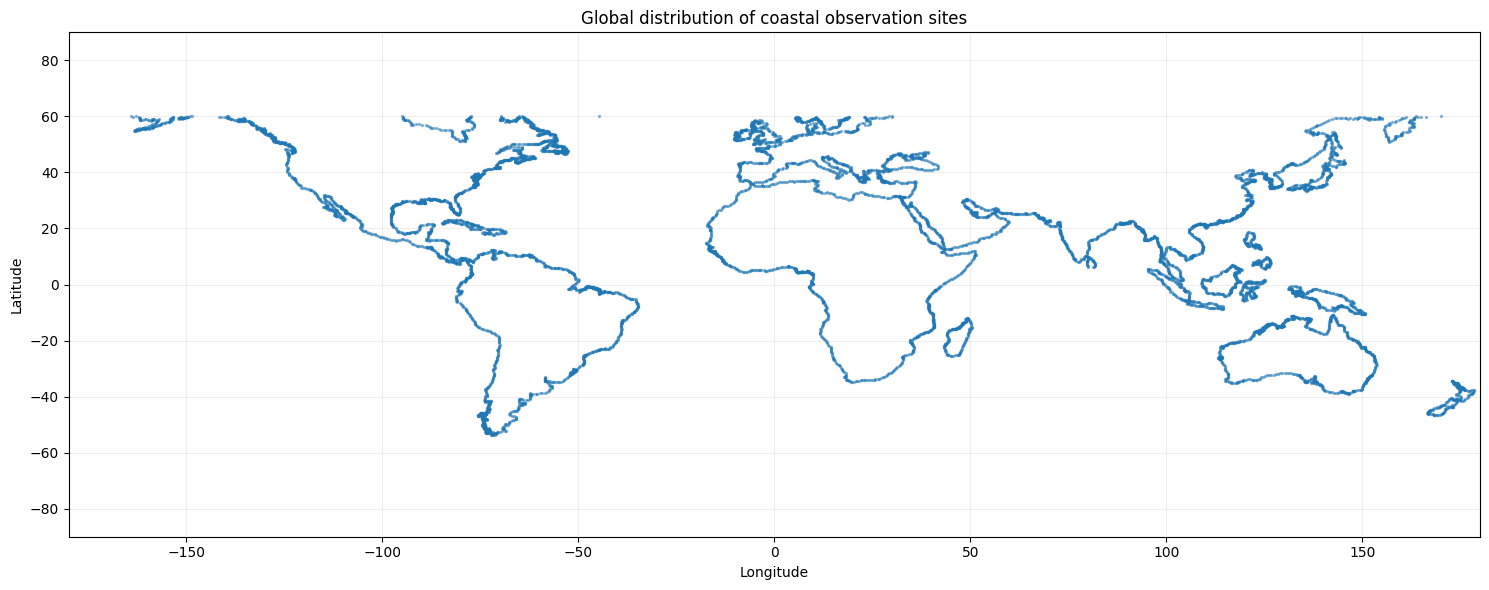

In [58]:
valid_geo = geo_df.loc[geo_df["Coordinates_Valid"]].copy()

plt.figure(figsize=(15, 6))
plt.scatter(valid_geo["Longitude"], valid_geo["Latitude"], s=2, alpha=0.45)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global distribution of coastal observation sites")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5.4 — Interactive global map with Folium

The map displays observation points. It does not infer national boundaries or coastline geometry. If rendering all sites is slow in your browser, use the sampled view in the next cell.

In [59]:
import folium

# Sample only for a responsive interactive map; the full table remains unchanged.
MAP_SAMPLE_SIZE = min(5000, len(valid_geo))
map_points = valid_geo.sample(n=MAP_SAMPLE_SIZE, random_state=42) if MAP_SAMPLE_SIZE else valid_geo

world_map = folium.Map(
    location=[20, 0],
    zoom_start=2,
    tiles="CartoDB positron"
)

for row in map_points.itertuples(index=False):
    folium.CircleMarker(
        location=[row.Latitude, row.Longitude],
        radius=2,
        color="#1677b8",
        fill=True,
        fill_opacity=0.55,
        weight=1,
        tooltip=f"Site {row.Site_Index}"
    ).add_to(world_map)

print(f"Displaying {len(map_points):,} of {len(valid_geo):,} valid sites.")
display(world_map)

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Displaying 5,000 of 8,841 valid sites.


## 5.5 — Parse the monthly time coordinate

The expected source format is `YYYYMM`. This cell validates and converts it to pandas timestamps.

In [61]:
raw_time = np.asarray(ds["time"].values)

time_text = (
    pd.Series(raw_time)
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(6)
)

dates = pd.to_datetime(time_text, format="%Y%m", errors="coerce")

if dates.isna().any():
    bad_values = pd.Series(raw_time)[dates.isna()].head(10).tolist()
    raise ValueError(f"Some time values could not be parsed as YYYYMM. Examples: {bad_values}")

print("Number of months:", len(dates))
print("First month:", dates.min())
print("Last month:", dates.max())
print("Duplicate months:", int(dates.duplicated().sum()))

Number of months: 324
First month: 1993-01-01 00:00:00
Last month: 2019-12-01 00:00:00
Duplicate months: 0


## 5.6 — Estimate per-site temporal trends in X

For each site, fit a simple linear regression of `X` against elapsed years. A minimum data-availability threshold is applied. Missing observations are ignored for that site's fit; no values are filled.

**Interpretation:** the slope is a trend in the dataset's detrended `X` values per year. It must not be labelled an absolute shoreline erosion/accretion rate without further scientific validation.

In [63]:
x_values = np.asarray(ds["X"].values, dtype=float)

if x_values.ndim != 2:
    raise ValueError(f"Expected X to be 2D (site, time), got shape {x_values.shape}")
if x_values.shape[1] != len(dates):
    raise ValueError("X time dimension does not match parsed time coordinate.")

elapsed_years = (dates - dates.min()).dt.days.to_numpy(dtype=float) / 365.25
trend_rows = []

MIN_VALID_MONTHS = 60

for site_idx in range(x_values.shape[0]):
    y = x_values[site_idx, :]
    mask = np.isfinite(y) & np.isfinite(elapsed_years)

    n_valid = int(mask.sum())
    if n_valid < MIN_VALID_MONTHS:
        trend_rows.append({
            "Site_Index": site_idx,
            "Valid_Months": n_valid,
            "Trend_X_per_Year": np.nan,
            "Intercept": np.nan,
            "R2": np.nan
        })
        continue

    slope, intercept = np.polyfit(elapsed_years[mask], y[mask], 1)
    fitted = slope * elapsed_years[mask] + intercept
    ss_res = np.sum((y[mask] - fitted) ** 2)
    ss_tot = np.sum((y[mask] - np.mean(y[mask])) ** 2)
    r2 = np.nan if ss_tot == 0 else 1 - ss_res / ss_tot

    trend_rows.append({
        "Site_Index": site_idx,
        "Valid_Months": n_valid,
        "Trend_X_per_Year": slope,
        "Intercept": intercept,
        "R2": r2
    })

trend_df = pd.DataFrame(trend_rows)
trend_geo_df = geo_df.merge(trend_df, on="Site_Index", how="left")

print("Sites with enough data:", int(trend_df["Trend_X_per_Year"].notna().sum()))
display(trend_geo_df.head())

Sites with enough data: 8840


,Site_Index,Latitude,Longitude,Coordinates_Valid,Valid_Months,Trend_X_per_Year,Intercept,R2
0,0,59.993333,170.150722,True,226,-1.203436,18.896485,0.067666
1,1,59.813750,166.256750,True,253,0.403817,-5.841592,0.024986
2,2,59.847861,165.059972,True,253,0.255568,-3.294765,0.006808
3,3,59.890806,164.124056,True,253,0.275973,-3.665556,0.007915
4,4,59.965833,163.785778,True,253,0.186100,-2.203470,0.003735


## 5.7 — Inspect the distribution of estimated trends

This plot shows the distribution of fitted slopes among sites that meet the minimum data threshold. It is descriptive and does not establish statistical significance.

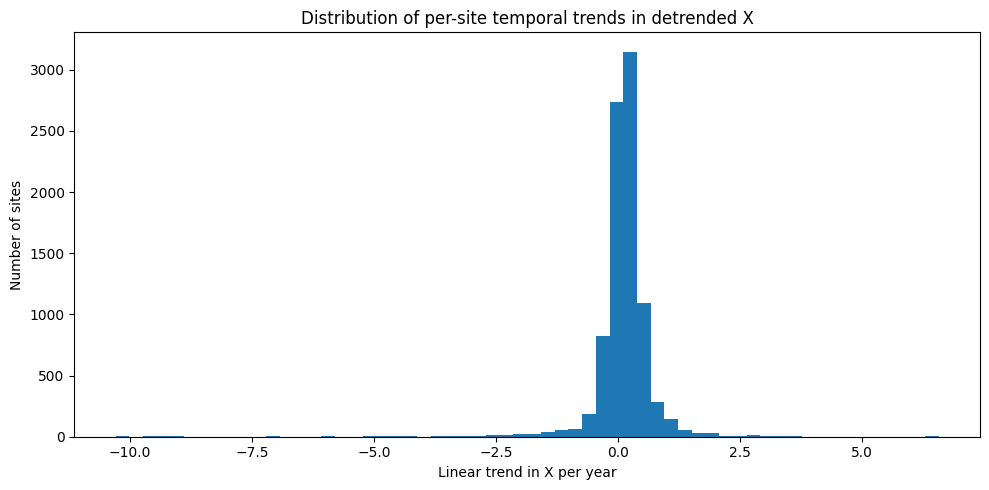

,Trend_X_per_Year
count,8840.000000
mean,0.113257
std,0.687768
min,-10.293914
25%,-0.043339
50%,0.139358
75%,0.322339
max,6.578552


In [64]:
valid_trends = trend_geo_df["Trend_X_per_Year"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(valid_trends, bins=60)
plt.xlabel("Linear trend in X per year")
plt.ylabel("Number of sites")
plt.title("Distribution of per-site temporal trends in detrended X")
plt.tight_layout()
plt.show()

display(trend_geo_df["Trend_X_per_Year"].describe())

## 5.8 — Map candidate high-magnitude trend sites

We display the top 1% of absolute fitted slopes as **candidate sites for investigation**, not as confirmed erosion hotspots. The threshold is data-driven and exploratory.

In [65]:
trend_map_df = trend_geo_df.dropna(subset=["Trend_X_per_Year"]).copy()

if trend_map_df.empty:
    print("No sites met the minimum data threshold.")
else:
    magnitude_threshold = trend_map_df["Trend_X_per_Year"].abs().quantile(0.99)
    candidates = trend_map_df[
        trend_map_df["Trend_X_per_Year"].abs() >= magnitude_threshold
    ].copy()

    print("Exploratory 99th-percentile absolute-trend threshold:", magnitude_threshold)
    print("Candidate sites:", len(candidates))
    display(candidates.sort_values("Trend_X_per_Year", key=lambda s: s.abs(), ascending=False).head(20))

    candidate_map = folium.Map(location=[20, 0], zoom_start=2, tiles="CartoDB positron")
    for row in candidates.itertuples(index=False):
        folium.CircleMarker(
            location=[row.Latitude, row.Longitude],
            radius=5,
            color="#c0392b" if row.Trend_X_per_Year < 0 else "#238b57",
            fill=True,
            fill_opacity=0.75,
            tooltip=f"Site {row.Site_Index} | slope={row.Trend_X_per_Year:.3f}"
        ).add_to(candidate_map)
    display(candidate_map)

Exploratory 99th-percentile absolute-trend threshold: 2.526552474575242
Candidate sites: 89


,Site_Index,Latitude,Longitude,Coordinates_Valid,Valid_Months,Trend_X_per_Year,Intercept,R2
5401,5401,2.689944,-77.850000,True,280,-10.293914,163.183280,0.131030
5393,5393,1.774361,-78.750361,True,279,-10.190531,170.140587,0.174729
5390,5390,1.245472,-78.885528,True,279,-9.774610,164.282068,0.157208
5389,5389,1.048333,-79.000000,True,279,-9.702116,168.827543,0.124007
5402,5402,2.734972,-77.790750,True,280,-9.586865,153.272490,0.113229
5392,5392,1.612472,-78.966944,True,279,-9.480625,158.370120,0.148720
5394,5394,1.766500,-78.530361,True,279,-9.420576,157.476463,0.151665
5399,5399,2.495333,-78.138861,True,280,-9.267098,152.892554,0.156198
5400,5400,2.641639,-77.977694,True,280,-9.004850,145.867038,0.143815
5398,5398,2.376806,-78.324583,True,280,-8.960287,147.126856,0.165003


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 5.9 — Tunisia case study: inspect the seven previously identified sites

These site indices were previously checked against a Tunisia administrative boundary. They form a preliminary subset only. This cell checks whether the indices exist in the current dataset and summarizes their coordinate and trend information.

In [66]:
tunisia_site_indices = [3142, 3150, 3155, 3156, 3158, 3163, 3164]

tunisia_df = trend_geo_df[
    trend_geo_df["Site_Index"].isin(tunisia_site_indices)
].copy().sort_values("Site_Index")

missing_tunisia_ids = sorted(set(tunisia_site_indices) - set(tunisia_df["Site_Index"]))
print("Requested Tunisia site count:", len(tunisia_site_indices))
print("Found:", len(tunisia_df))
print("Not found:", missing_tunisia_ids)

display(tunisia_df)

Requested Tunisia site count: 7
Found: 7
Not found: []


,Site_Index,Latitude,Longitude,Coordinates_Valid,Valid_Months,Trend_X_per_Year,Intercept,R2
3142,3142,37.230389,9.331639,True,324,0.418286,-4.594154,2.417131e-01
3150,3150,36.811250,11.052444,True,324,0.149370,-2.048625,6.784381e-02
3155,3155,35.061639,11.021194,True,324,-0.000067,-0.398248,1.602995e-08
3156,3156,34.722472,10.756250,True,324,0.037664,-0.756796,5.888634e-03
3158,3158,34.291639,10.097056,True,324,0.002489,-0.564040,2.451483e-05
3163,3163,33.299528,11.249083,True,324,0.075949,-1.211933,1.833868e-02
3164,3164,33.205333,11.267444,True,324,0.092300,-1.360279,2.587655e-02


## 5.10 — Interactive Tunisia site map

The map focuses on the seven selected points. It is not a complete representation of the Tunisian coastline.

In [67]:
if not tunisia_df.empty:
    center_lat = tunisia_df["Latitude"].mean()
    center_lon = tunisia_df["Longitude"].mean()

    tunisia_map = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=6,
        tiles="CartoDB positron"
    )

    for row in tunisia_df.itertuples(index=False):
        popup_text = (
            f"Site: {row.Site_Index}<br>"
            f"Latitude: {row.Latitude:.5f}<br>"
            f"Longitude: {row.Longitude:.5f}<br>"
            f"Valid months: {row.Valid_Months}<br>"
            f"X trend/year: {row.Trend_X_per_Year}"
        )
        folium.CircleMarker(
            location=[row.Latitude, row.Longitude],
            radius=7,
            color="#7b3294",
            fill=True,
            fill_opacity=0.8,
            popup=folium.Popup(popup_text, max_width=300),
            tooltip=f"Tunisia Site {row.Site_Index}"
        ).add_to(tunisia_map)

    display(tunisia_map)
else:
    print("No Tunisia sites found. Check the dataset and site indices.")

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 5.11 — Compare monthly X series for the Tunisia sites

This plot shows observed values only. Gaps remain gaps; no interpolation or imputation is applied.

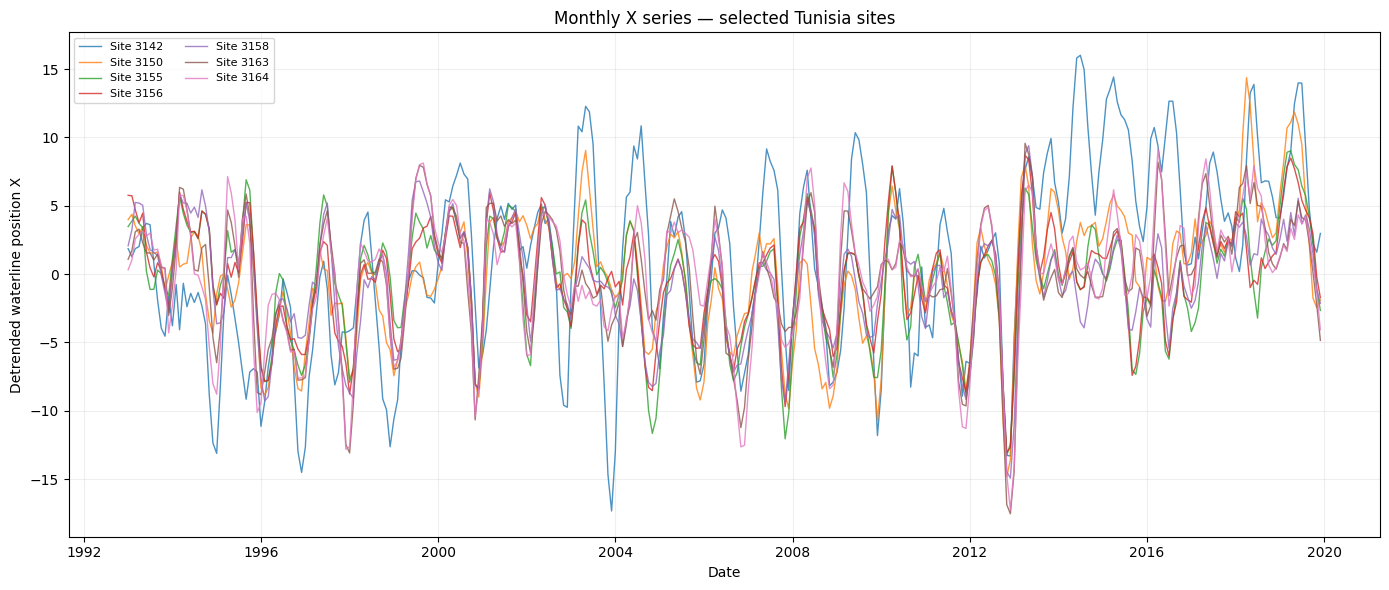

In [68]:
plt.figure(figsize=(14, 6))

for site_idx in tunisia_site_indices:
    if site_idx < x_values.shape[0]:
        series = x_values[site_idx, :]
        plt.plot(dates, series, linewidth=1, alpha=0.8, label=f"Site {site_idx}")

plt.xlabel("Date")
plt.ylabel("Detrended waterline position X")
plt.title("Monthly X series — selected Tunisia sites")
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5.12 — Export geospatial and trend results

Exports include the complete site-coordinate table, per-site trend results, and the selected Tunisia subset.

In [69]:
geo_df.to_csv("CoastGuard_TN_Phase5_Global_Site_Coordinates.csv", index=False)
trend_geo_df.to_csv("CoastGuard_TN_Phase5_Global_Site_Trends.csv", index=False)
tunisia_df.to_csv("CoastGuard_TN_Phase5_Tunisia_Sites.csv", index=False)

print("Exported:")
print("- CoastGuard_TN_Phase5_Global_Site_Coordinates.csv")
print("- CoastGuard_TN_Phase5_Global_Site_Trends.csv")
print("- CoastGuard_TN_Phase5_Tunisia_Sites.csv")

Exported:
- CoastGuard_TN_Phase5_Global_Site_Coordinates.csv
- CoastGuard_TN_Phase5_Global_Site_Trends.csv
- CoastGuard_TN_Phase5_Tunisia_Sites.csv


## 5.13 — Download Phase 5 outputs

Run in Google Colab to download the CSV outputs.

In [70]:
from google.colab import files

for filename in [
    "CoastGuard_TN_Phase5_Global_Site_Coordinates.csv",
    "CoastGuard_TN_Phase5_Global_Site_Trends.csv",
    "CoastGuard_TN_Phase5_Tunisia_Sites.csv"
]:
    if os.path.exists(filename):
        files.download(filename)
    else:
        print("Not found:", filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 5 — Summary and next steps

This phase creates:
- A geographic table for all observation sites.
- A global point distribution plot and interactive map.
- Per-site linear trends in detrended `X`, subject to a minimum valid-data threshold.
- An exploratory map of the highest-magnitude trends.
- A focused view of the seven selected Tunisia sites.
- CSV exports for later platform integration.

### Limitations to address before publication
1. Confirm the `lat[i]` / `lon[i]` / `X[i, :]` site correspondence in the official dataset documentation.
2. Review coordinate reference system and dataset spatial resolution.
3. Use formal statistical tests and confidence intervals for trend estimates.
4. Account for spatial autocorrelation and multiple comparisons before hotspot claims.
5. Validate with independent shoreline observations or authoritative coastal datasets.
6. Expand the Tunisia subset before making country-wide conclusions.

**Next phase proposal:** Phase 6 — Big Data engineering and platform integration (data storage, spatial database, API, and dashboard).

# PHASE 6 — Big Data Engineering & Data Lake with Apache Spark

**Objective:** transform the global NetCDF observations into a scalable, columnar Parquet data lake and create global monthly and per-site analytics using PySpark.

**Architecture:** NetCDF (Raw) → batch conversion → Parquet (Processed) → Apache Spark → Analytics (Parquet/CSV).

**Important:** this notebook uses Spark in `local[*]` mode inside Google Colab. It demonstrates a Spark batch-processing pipeline, but it is not a multi-node production cluster. Missing environmental observations are preserved; no missing values are replaced with zero, and no observations are deleted.


## 6.1 — Install and import Big Data libraries
Run this cell once in the Colab runtime. If Colab asks to restart the runtime, restart it and run the notebook again from the beginning.


In [71]:
!pip -q install pyspark pyarrow fastparquet xarray netCDF4

import os
import shutil
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path
from pyspark.sql import SparkSession, functions as F


## 6.2 — Reuse and validate the NetCDF dataset
The earlier phases load the dataset into `ds`. If this cell is run independently or `ds` is not available, it asks you to upload the original NetCDF file.


In [72]:
if 'ds' not in globals():
    from google.colab import files
    uploaded = files.upload()
    nc_candidates = [name for name in uploaded if name.lower().endswith('.nc')]
    if not nc_candidates:
        raise FileNotFoundError('Upload GlobalWaterlineDataset.nc')
    DATASET_PATH = nc_candidates[0]
    ds = xr.open_dataset(DATASET_PATH)
else:
    DATASET_PATH = globals().get('DATASET_PATH', None)

if DATASET_PATH is None or not os.path.exists(DATASET_PATH):
    # Save a local copy of the currently opened xarray dataset when the original path is unavailable.
    DATASET_PATH = '/content/CoastGuard_Phase6_source.nc'
    ds.to_netcdf(DATASET_PATH)

required_variables = ['X', 'River_drivers', 'SLA_drivers', 'Wave_Hs_drivers', 'Wave_Tp_drivers', 'Wave_Dir_drivers']
missing_variables = [v for v in required_variables if v not in ds.data_vars]
if missing_variables:
    raise ValueError(f'Missing required variables: {missing_variables}')

site_dim = ds['lon'].dims[0]
time_dim = ds['time'].dims[0]
if site_dim not in ds.sizes or time_dim not in ds.sizes:
    raise ValueError('Could not identify site and time dimensions from lon/time coordinates.')

site_count = ds.sizes[site_dim]
time_count = ds.sizes[time_dim]
print('Dataset validated')
print('Sites:', site_count, '| Months:', time_count)
print('Variables:', required_variables)


Dataset validated
Sites: 8841 | Months: 324
Variables: ['X', 'River_drivers', 'SLA_drivers', 'Wave_Hs_drivers', 'Wave_Tp_drivers', 'Wave_Dir_drivers']


## 6.3 — Create the Data Lake folder structure
We separate the original source data, transformed Parquet batches, and analytical outputs.


In [73]:
from google.colab import files

BASE_DIR = Path('/content/CoastGuard_DataLake')
RAW_DIR = BASE_DIR / 'raw'
PROCESSED_DIR = BASE_DIR / 'processed' / 'site_month'
ANALYTICS_DIR = BASE_DIR / 'analytics'

for folder in [RAW_DIR, PROCESSED_DIR, ANALYTICS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

raw_copy = RAW_DIR / 'GlobalWaterlineDataset.nc'
if os.path.abspath(DATASET_PATH) != os.path.abspath(raw_copy):
    shutil.copy2(DATASET_PATH, raw_copy)

print('Data Lake created at:', BASE_DIR)
for folder in [RAW_DIR, PROCESSED_DIR, ANALYTICS_DIR]:
    print('-', folder)


Data Lake created at: /content/CoastGuard_DataLake
- /content/CoastGuard_DataLake/raw
- /content/CoastGuard_DataLake/processed/site_month
- /content/CoastGuard_DataLake/analytics


## 6.4 — Parse the monthly time coordinate
The source time values are expected to use the `YYYYMM` format. We validate this before writing the data lake.


In [74]:
time_raw = np.asarray(ds['time'].values).astype(int)
dates = pd.to_datetime(time_raw.astype(str), format='%Y%m', errors='coerce')
if pd.isna(dates).any():
    raise ValueError('Some time values could not be parsed as YYYYMM.')

print('Start:', dates.min())
print('End:', dates.max())
print('Number of months:', len(dates))


Start: 1993-01-01 00:00:00
End: 2019-12-01 00:00:00
Number of months: 324


## 6.5 — Batch conversion from NetCDF to Parquet
We process a limited number of sites per batch to avoid creating one very large in-memory DataFrame. Each output row represents one site-month. The original values and missing values are preserved.


In [75]:
BATCH_SIZE = 250
written_batches = 0

for start in range(0, site_count, BATCH_SIZE):
    stop = min(start + BATCH_SIZE, site_count)
    batch_size = stop - start

    batch = {
        'site_index': np.repeat(np.arange(start, stop, dtype=np.int32), time_count),
        'time': np.tile(dates, batch_size),
        'lat': np.repeat(np.asarray(ds['lat'].values[start:stop], dtype=np.float64), time_count),
        'lon': np.repeat(np.asarray(ds['lon'].values[start:stop], dtype=np.float64), time_count),
    }

    for variable in required_variables:
        values = ds[variable].transpose(site_dim, time_dim).isel({site_dim: slice(start, stop)}).values
        values = np.asarray(values, dtype=np.float64)
        batch[variable] = values.reshape(-1)

    batch_df = pd.DataFrame(batch)
    output_file = PROCESSED_DIR / f'batch_{start:05d}_{stop:05d}.parquet'
    batch_df.to_parquet(output_file, index=False, engine='pyarrow')
    written_batches += 1

    print(f'Wrote sites {start}–{stop-1}: {len(batch_df):,} rows')
    del batch_df, batch

print(f'Parquet conversion complete: {written_batches} batches')


Wrote sites 0–249: 81,000 rows
Wrote sites 250–499: 81,000 rows
Wrote sites 500–749: 81,000 rows
Wrote sites 750–999: 81,000 rows
Wrote sites 1000–1249: 81,000 rows
Wrote sites 1250–1499: 81,000 rows
Wrote sites 1500–1749: 81,000 rows
Wrote sites 1750–1999: 81,000 rows
Wrote sites 2000–2249: 81,000 rows
Wrote sites 2250–2499: 81,000 rows
Wrote sites 2500–2749: 81,000 rows
Wrote sites 2750–2999: 81,000 rows
Wrote sites 3000–3249: 81,000 rows
Wrote sites 3250–3499: 81,000 rows
Wrote sites 3500–3749: 81,000 rows
Wrote sites 3750–3999: 81,000 rows
Wrote sites 4000–4249: 81,000 rows
Wrote sites 4250–4499: 81,000 rows
Wrote sites 4500–4749: 81,000 rows
Wrote sites 4750–4999: 81,000 rows
Wrote sites 5000–5249: 81,000 rows
Wrote sites 5250–5499: 81,000 rows
Wrote sites 5500–5749: 81,000 rows
Wrote sites 5750–5999: 81,000 rows
Wrote sites 6000–6249: 81,000 rows
Wrote sites 6250–6499: 81,000 rows
Wrote sites 6500–6749: 81,000 rows
Wrote sites 6750–6999: 81,000 rows
Wrote sites 7000–7249: 81,000 

## 6.6 — Start Apache Spark and read Parquet
Spark reads the batch files as one logical dataset. The `local[*]` setting uses the CPU cores available in this Colab runtime.


In [80]:
spark = (
    SparkSession.builder
    .appName('CoastGuardTN_BigData_Phase6')
    .master('local[*]')
    .config('spark.sql.shuffle.partitions', '8')
    .config('spark.sql.parquet.nanosAsLong', 'true')
    .config('spark.sql.parquet.nanosecond.precision.allowed', 'true')
    .config('spark.sql.legacy.parquet.nanosAsLong', 'true')
    .getOrCreate()
)
spark.sparkContext.setLogLevel('ERROR')

# Read Parquet files, allowing legacy nanoseconds as long
spark_df = spark.read.parquet(str(PROCESSED_DIR / '*.parquet'))

# Cast the 'time' column (which is read as a Long of nanoseconds) to a proper Timestamp
# Divide nanoseconds by 1,000,000,000 to get seconds, and cast to timestamp
spark_df = spark_df.withColumn('time', (F.col('time').cast('double') / 1000000000).cast('timestamp'))

print('Spark version:', spark.version)
print('Total site-month rows:', f'{spark_df.count():,}')
spark_df.printSchema()
spark_df.show(5, truncate=False)

Spark version: 4.0.5
Total site-month rows: 2,864,484
root
 |-- site_index: integer (nullable = true)
 |-- time: timestamp (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- X: double (nullable = true)
 |-- River_drivers: double (nullable = true)
 |-- SLA_drivers: double (nullable = true)
 |-- Wave_Hs_drivers: double (nullable = true)
 |-- Wave_Tp_drivers: double (nullable = true)
 |-- Wave_Dir_drivers: double (nullable = true)

+----------+-------------------+---------+----------+----+------------------+---------------------+------------------+------------------+------------------+
|site_index|time               |lat      |lon       |X   |River_drivers     |SLA_drivers          |Wave_Hs_drivers   |Wave_Tp_drivers   |Wave_Dir_drivers  |
+----------+-------------------+---------+----------+----+------------------+---------------------+------------------+------------------+------------------+
|0         |1993-01-01 00:00:00|59.993333|170.150722|N

## 6.7 — Data Quality checks
We verify row counts, distinct sites/months, missing-value counts, and duplicate site-month keys. Missing values are reported, not imputed.


In [81]:
spark_df.select(
    F.count('*').alias('total_rows'),
    F.countDistinct('site_index').alias('unique_sites'),
    F.countDistinct('time').alias('unique_months')
).show(truncate=False)

missing_report = spark_df.select(*[
    F.sum(F.col(c).isNull().cast('long')).alias(c)
    for c in required_variables
])
missing_report.show(truncate=False)

duplicate_count = (
    spark_df.groupBy('site_index', 'time')
    .count()
    .filter(F.col('count') > 1)
    .count()
)
print('Duplicate site-month keys:', duplicate_count)


+----------+------------+-------------+
|total_rows|unique_sites|unique_months|
+----------+------------+-------------+
|2864484   |8841        |324          |
+----------+------------+-------------+

+------+-------------+-----------+---------------+---------------+----------------+
|X     |River_drivers|SLA_drivers|Wave_Hs_drivers|Wave_Tp_drivers|Wave_Dir_drivers|
+------+-------------+-----------+---------------+---------------+----------------+
|102727|428281       |0          |0              |0              |0               |
+------+-------------+-----------+---------------+---------------+----------------+

Duplicate site-month keys: 0


## 6.8 — Global monthly analytics
For each month, calculate the number of site records and summary statistics for waterline position and environmental drivers. These are descriptive global aggregates, not causal conclusions.


In [82]:
monthly_analytics = (
    spark_df.groupBy('time')
    .agg(
        F.count('*').alias('site_month_records'),
        F.count('X').alias('valid_X_records'),
        F.avg('X').alias('mean_X'),
        F.stddev('X').alias('std_X'),
        F.avg('SLA_drivers').alias('mean_SLA'),
        F.avg('Wave_Hs_drivers').alias('mean_Wave_Hs'),
        F.avg('Wave_Tp_drivers').alias('mean_Wave_Tp'),
        F.avg('Wave_Dir_drivers').alias('mean_Wave_Dir')
    )
    .orderBy('time')
)
monthly_analytics.show(12, truncate=False)


+-------------------+------------------+---------------+--------------------+------------------+----------------------+------------------+------------------+------------------+
|time               |site_month_records|valid_X_records|mean_X              |std_X             |mean_SLA              |mean_Wave_Hs      |mean_Wave_Tp      |mean_Wave_Dir     |
+-------------------+------------------+---------------+--------------------+------------------+----------------------+------------------+------------------+------------------+
|1993-01-01 00:00:00|8841              |6839           |0.7770610003803502  |29.98063579462876 |-0.028044451182408937 |0.8992388090158061|7.01500864213207  |183.42909263713307|
|1993-02-01 00:00:00|8841              |6995           |-0.14998534902646668|25.915477423132465|-0.026704122503203868 |0.847746199147667 |7.002627078498515 |184.35083873376743|
|1993-03-01 00:00:00|8841              |7156           |0.07516582580806795 |25.384100485021754|-0.0228736996557417

## 6.9 — Per-site analytics
Create a compact profile for every site, including valid waterline observations and average environmental conditions.


In [83]:
site_analytics = (
    spark_df.groupBy('site_index', 'lat', 'lon')
    .agg(
        F.count('X').alias('valid_X_count'),
        F.avg('X').alias('mean_X'),
        F.stddev('X').alias('std_X'),
        F.avg('SLA_drivers').alias('mean_SLA'),
        F.avg('Wave_Hs_drivers').alias('mean_Wave_Hs'),
        F.avg('Wave_Tp_drivers').alias('mean_Wave_Tp')
    )
    .orderBy('site_index')
)
site_analytics.show(10, truncate=False)


+----------+---------+----------+-------------+-------------------+------------------+----------------------+------------------+-----------------+
|site_index|lat      |lon       |valid_X_count|mean_X             |std_X             |mean_SLA              |mean_Wave_Hs      |mean_Wave_Tp     |
+----------+---------+----------+-------------+-------------------+------------------+----------------------+------------------+-----------------+
|0         |59.993333|170.150722|226          |-0.5471028261704667|28.029611780856023|2.440278461972973E-4  |2.1552322761875833|9.111626295302983|
|1         |59.81375 |166.25675 |253          |0.7530064803691721 |15.992446104930947|-4.2916332169602635E-4|1.7705060385955123|9.139621156662754|
|2         |59.847861|165.059972|253          |0.878828360253702  |19.389418563261128|-8.977767450255389E-4 |1.5170919872236615|8.907571009705812|
|3         |59.890806|164.124056|253          |0.8412633829772207 |19.418471156549682|-7.497113962006237E-4 |1.2428189

## 6.10 — Save Analytics as Parquet and CSV
Parquet is the primary analytical storage format. CSV copies are also created for convenient inspection and integration.


In [84]:
monthly_parquet = ANALYTICS_DIR / 'monthly_analytics_parquet'
site_parquet = ANALYTICS_DIR / 'site_analytics_parquet'

monthly_analytics.write.mode('overwrite').parquet(str(monthly_parquet))
site_analytics.write.mode('overwrite').parquet(str(site_parquet))

monthly_pd = monthly_analytics.toPandas()
site_pd = site_analytics.toPandas()
monthly_pd.to_csv(ANALYTICS_DIR / 'monthly_analytics.csv', index=False)
site_pd.to_csv(ANALYTICS_DIR / 'site_analytics.csv', index=False)

print('Analytics exports saved in:', ANALYTICS_DIR)


Analytics exports saved in: /content/CoastGuard_DataLake/analytics


## 6.11 — Visualize global monthly results
The chart displays the monthly mean of the detrended waterline position `X`. Interpret it as a global descriptive series, not as an absolute shoreline-change rate.


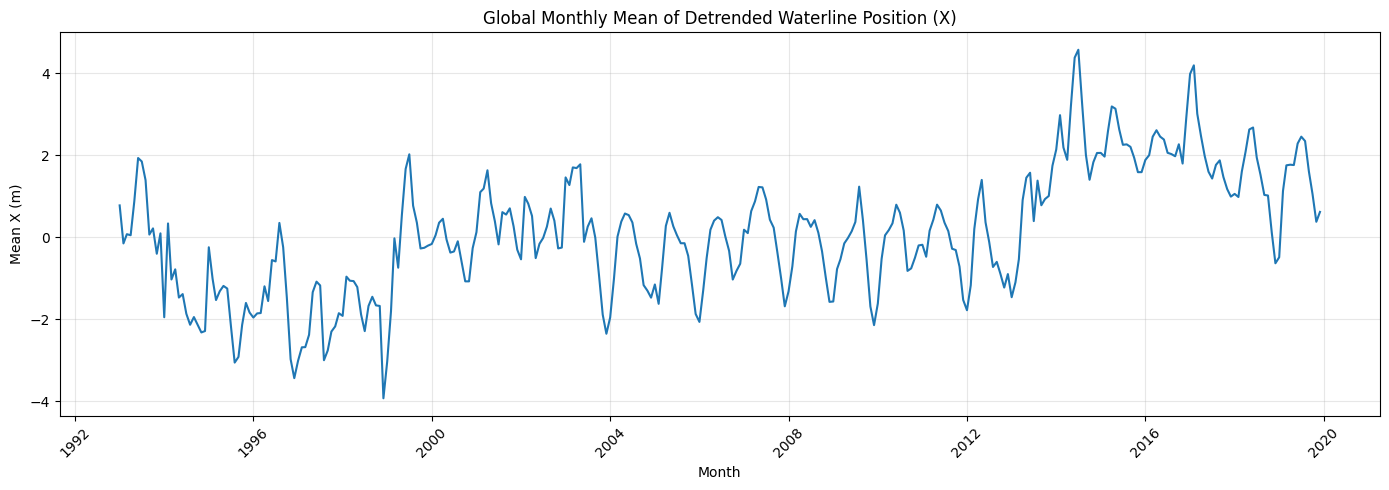

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(monthly_pd['time'], monthly_pd['mean_X'])
plt.title('Global Monthly Mean of Detrended Waterline Position (X)')
plt.xlabel('Month')
plt.ylabel('Mean X (m)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 6.12 — Data Lake inventory and final validation


In [86]:
def folder_size_bytes(path):
    return sum(p.stat().st_size for p in Path(path).rglob('*') if p.is_file())

print('========== COASTGUARD TN DATA LAKE ==========')
print('Raw source exists:', (RAW_DIR / 'GlobalWaterlineDataset.nc').exists())
print('Parquet batch files:', len(list(PROCESSED_DIR.glob('*.parquet'))))
print('Analytics files/folders:', [p.name for p in ANALYTICS_DIR.iterdir()])
print('Processed size (MB):', round(folder_size_bytes(PROCESSED_DIR) / (1024**2), 2))
print('Spark rows:', f'{spark_df.count():,}')
print('Distinct sites:', spark_df.select('site_index').distinct().count())
print('Distinct months:', spark_df.select('time').distinct().count())
print('Duplicate site-month keys:', duplicate_count)


========== COASTGUARD TN DATA LAKE ==========
Raw source exists: True
Parquet batch files: 36
Analytics files/folders: ['monthly_analytics_parquet', 'site_analytics.csv', 'monthly_analytics.csv', 'site_analytics_parquet']
Processed size (MB): 99.7
Spark rows: 2,864,484
Distinct sites: 8841
Distinct months: 324
Duplicate site-month keys: 0


## 6.13 — Download the complete Phase 6 Data Lake
The ZIP includes the raw NetCDF source, processed Parquet batches, and analytical outputs. It may be large, so ensure you have enough local storage.


In [87]:
from google.colab import files

zip_base = '/content/CoastGuard_TN_Phase6_DataLake'
zip_path = shutil.make_archive(zip_base, 'zip', root_dir=BASE_DIR)
print('ZIP size (MB):', round(os.path.getsize(zip_path) / (1024**2), 2))
files.download(zip_path)


ZIP size (MB): 139.57


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 6 — Summary and scientific limitations

**Delivered by this phase:**
- A Raw / Processed / Analytics Data Lake structure.
- Batch conversion of the NetCDF dataset into Parquet.
- Spark-based batch reading and quality checks.
- Global monthly and per-site descriptive analytics.
- Parquet and CSV exports for downstream services.

**Interpretation and limitations:**
1. Spark runs locally in Colab (`local[*]`); a true distributed deployment would require a multi-node cluster.
2. This phase preserves missing values and does not perform automatic imputation or outlier deletion.
3. The monthly aggregates summarize the available sites; they do not imply uniform geographic coverage.
4. `X` is the dataset's detrended waterline position. Do not label its mean or trends as absolute shoreline displacement without confirming the dataset's scientific definition.
5. The data lake is a Colab working directory. Download the ZIP before the runtime disconnects.

**Next integration stage:** load selected analytics into PostgreSQL/PostGIS, expose them through FastAPI, and connect the API to the Angular dashboard.


In [88]:
# Stop Spark after all Phase 6 computations and exports are complete.
spark.stop()
print('Phase 6 pipeline completed.')


Phase 6 pipeline completed.
